# **Project Title:** AI-Powered IoT Network Anomaly Detection and Investigation Platform

## Phase 3B: XGBoost Meta-Model — Reuse Existing Stacking Artifacts

| Item | Details |
|---|---|
| Source notebook | `ciciot2023-do-an-stacking.ipynb` |
| Source stacking run | `stacking_20261021_064141_916da555` (có thể đổi trong cấu hình) |
| Source data run | Lấy từ `protocol.json` của stacking run, không tự chọn dữ liệu khác |
| Base models | DT, RF, HGB **đã fit**, nạp từ bundle đã freeze |
| Meta input | 24 xác suất OOF: DT → RF → HGB, mỗi model đủ 8 lớp |
| New training | Chỉ fit XGBoost meta-model; không fit lại base/preprocessor hoặc tạo lại fold |
| Selection | Macro-F1 trên validation; giữ LR cũ làm đối chứng |
| Output | `/kaggle/working/stacking_meta_runs/<run_id>/` |

**Chưa chạy notebook này trên Kaggle.** Giữ phong cách output như EDA: tiêu đề, bảng, confusion matrix và summary.

### Required Kaggle Inputs

Gắn **hai thư mục output đầy đủ**, giữ nguyên cấu trúc bên trong:

1. `processed_data/<data_run_id>/` — config, schema, checksums, X/y, group ID, metadata và fold ID.
2. `stacking_runs/<source_run_id>/` — protocol/status, `oof/`, `validation_*_probabilities.npy`,
   `frozen_candidates.json`, `frozen_models/`, bảng validation, audit và reference hashes.

Nếu chỉ có bundle model mà thiếu OOF, không thể thực hiện lượt train meta này.
`STACKING_DIR=None`, `DATA_DIR=None` tự tìm đúng run đã chỉ định; nếu có nhiều bản trùng, điền đường dẫn cụ thể.

Dùng cùng phiên bản NumPy, pandas, scikit-learn và joblib như stacking run gốc. Nếu thiếu XGBoost, cài trong Kaggle rồi restart trước Run All; không tự nâng các thư viện của base models.


## Experiment Rules

- Giữ split Kaggle có sẵn, seed/fold và thứ tự lớp: Normal, BruteForce, DDoS, DoS, Mirai, Recon, Spoofing, Web-Based.
- XGBoost chỉ học từ **OOF + y_train**. Không thay OOF bằng dự đoán của full-train base models trên train.
- Tái sử dụng các xác suất validation đã lưu; đối chiếu với bundle gốc để phát hiện sai run/thứ tự dòng hoặc lớp.
- Khóa trước 6 cấu hình XGBoost. Số boosting rounds cố định, không early stopping trên validation/test.
- Không resampling; thử trọng số nhẹ cố định cho hai lớp hiếm ở một số cấu hình, không dùng `scale_pos_weight` cho bài toán 8 lớp.
- Chọn best XGBoost và so sánh với LR gốc bằng validation; nếu LR vẫn tốt hơn, giữ LR là ứng viên chính.
- Freeze cả hai trước khi đọc X_test/y_test. Test đã từng được xem trong run cũ: kết quả mới chỉ là so sánh trên test đã sử dụng, không tuyên bố xác nhận độc lập mới.
- Xuất metric từng lớp, macro-F1, confusion matrices, thời gian train meta/inference và phần cứng.

Tham khảo: [XGBoost multiclass parameters](https://xgboost.readthedocs.io/en/stable/parameter.html),
[XGBoost sklearn interface](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html),
[model IO](https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html).


# Import Library


In [1]:
import gc
import importlib.util
import json
import hashlib
import os
import platform
import shutil
import time
import uuid
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from threadpoolctl import threadpool_info, threadpool_limits

try:
    import xgboost
    from xgboost import XGBClassifier
except ImportError as error:
    raise RuntimeError(
        "Kaggle chưa có xgboost. Cài xgboost trong notebook setup rồi restart trước Run All; "
        "giữ nguyên các phiên bản thư viện của source stacking run."
    ) from error

## 1. Configuration — Freeze Search Space Before Training


In [2]:
DATA_DIR = "/kaggle/input/notebooks/phungdinhdat/ciciot2023-do-an-processing/processed_data/20261021_052521_96f61f19"
# Ví dụ: Path("/kaggle/input/<dataset>/stacking_runs/<source_run_id>")
STACKING_DIR = "/kaggle/input/notebooks/phungdinhdat/ciciot2023-do-an-stacking/stacking_runs/stacking_20261021_064141_916da555"      
# Ví dụ: Path("/kaggle/input/<dataset>/processed_data/<data_run_id>")
SOURCE_RUN_ID = "stacking_20261021_064141_916da555"
RANDOM_STATE = 42
N_JOBS = 2
BATCH_SIZE = 25_000
GOLDEN_SAMPLE_SIZE = 32
PROTOCOL = "stacking_xgb_meta_v1"

CLASS_NAMES = [
    "Normal", "BruteForce", "DDoS", "DoS",
    "Mirai", "Recon", "Spoofing", "Web-Based",
]
CLASS_IDS = np.arange(len(CLASS_NAMES))
BASE_NAMES = ["DT", "RF", "HGB"]

# Không thay lưới này sau khi đã xem kết quả test của lượt mới.
XGB_CONFIGS = [
    {"name": "XGB_d2_n100", "max_depth": 2, "n_estimators": 100, "reg_lambda": 5.0, "rare_weight": 1.0},
    {"name": "XGB_d3_n100", "max_depth": 3, "n_estimators": 100, "reg_lambda": 5.0, "rare_weight": 1.0},
    {"name": "XGB_d3_n200", "max_depth": 3, "n_estimators": 200, "reg_lambda": 5.0, "rare_weight": 1.0},
    {"name": "XGB_d4_n200", "max_depth": 4, "n_estimators": 200, "reg_lambda": 5.0, "rare_weight": 1.0},
    {"name": "XGB_d3_n200_l2_10", "max_depth": 3, "n_estimators": 200, "reg_lambda": 10.0, "rare_weight": 1.0},
    {"name": "XGB_d3_n200_rare2", "max_depth": 3, "n_estimators": 200, "reg_lambda": 5.0, "rare_weight": 2.0},
]
XGB_COMMON_PARAMS = {
    "objective": "multi:softprob", "num_class": len(CLASS_NAMES),
    "eval_metric": "mlogloss", "tree_method": "hist",
    "learning_rate": 0.05, "min_child_weight": 5.0,
    "subsample": 0.8, "colsample_bytree": 0.8, "reg_alpha": 0.0,
    "random_state": RANDOM_STATE, "n_jobs": N_JOBS,
}

if not Path("/kaggle/input").is_dir() or not Path("/kaggle/working").is_dir():
    raise RuntimeError("Chỉ train meta-model trên Kaggle.")

RUN_ID = "xgb_meta_" + time.strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8]
OUTPUT_DIR = Path("/kaggle/working/stacking_meta_runs") / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
SESSION_START = time.perf_counter()
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("=" * 70)
print("XGBOOST META-MODEL CONFIGURATION")
print("=" * 70)
print(f"Source run      : {SOURCE_RUN_ID}")
print(f"New run         : {RUN_ID}")
print(f"Meta candidates : {len(XGB_CONFIGS)}")
print("Base models     : reuse DT, RF, HGB; zero new base-model fits")
print("Selection       : validation macro-F1; keep LR on a tie")
print(f"XGBoost version : {xgboost.__version__}")

XGBOOST META-MODEL CONFIGURATION
Source run      : stacking_20261021_064141_916da555
New run         : xgb_meta_20261021_092334_9024562d
Meta candidates : 6
Base models     : reuse DT, RF, HGB; zero new base-model fits
Selection       : validation macro-F1; keep LR on a tie
XGBoost version : 3.4.1


### Helper Functions — Files and Probability Checks


In [3]:
def write_json(path, content):
    path.parent.mkdir(parents=True, exist_ok=True)
    text = json.dumps(content, indent=2, ensure_ascii=False, allow_nan=False)
    path.write_text(text, encoding="utf-8")


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        block = file.read(8 * 1024 * 1024)
        while block:
            digest.update(block)
            block = file.read(8 * 1024 * 1024)
    return digest.hexdigest()

def check_classes(targets, description):
    if not np.array_equal(np.unique(targets), CLASS_IDS):
        raise ValueError(f"{description}: cần đủ nhãn 0–7 theo thứ tự cố định.")

def check_probability_matrix(values, expected_rows, description):
    if values.shape != (expected_rows, len(CLASS_NAMES)) or values.dtype != np.float32:
        raise ValueError(f"{description}: shape/dtype không khớp xác suất float32 8 lớp.")
    for start in range(0, len(values), BATCH_SIZE):
        block = values[start:start + BATCH_SIZE]
        if not np.isfinite(block).all() or np.any(block < 0) or np.any(block > 1):
            raise ValueError(f"{description}: xác suất không hợp lệ.")
        if not np.allclose(block.sum(axis=1), 1.0, atol=1e-5):
            raise ValueError(f"{description}: tổng xác suất không bằng 1.")

def model_probabilities(model, values):
    if not np.array_equal(model.classes_, CLASS_IDS):
        raise ValueError("Thứ tự classes_ không khớp 8 lớp.")
    result = np.empty((len(values), len(CLASS_NAMES)), dtype=np.float32)
    with threadpool_limits(limits=N_JOBS):
        for start in range(0, len(values), BATCH_SIZE):
            stop = min(start + BATCH_SIZE, len(values))
            result[start:stop] = model.predict_proba(values[start:stop])
    check_probability_matrix(result, len(values), "model prediction")
    return result

def record_source(path, category):
    source_files.append({
        "category": category, "path": str(path),
        "bytes": int(path.stat().st_size), "sha256": sha256_file(path),
    })

## 2. Locate the Completed Source Stacking Run


In [4]:
print("=" * 70)
print("LOCATE SOURCE STACKING RUN")
print("=" * 70)

if STACKING_DIR is None:
    candidates = []
    for path in Path("/kaggle/input").rglob("protocol.json"):
        content = json.loads(path.read_text())
        if content.get("run_id") == SOURCE_RUN_ID:
            candidates.append(path.parent)
    if len(candidates) != 1:
        raise ValueError(f"Điền STACKING_DIR rõ ràng; các thư mục tìm được: {candidates}")
    STACKING_DIR = candidates[0]
else:
    STACKING_DIR = Path(STACKING_DIR)

source_protocol = json.loads((STACKING_DIR / "protocol.json").read_text())
source_status = json.loads((STACKING_DIR / "run_status.json").read_text())
source_freeze = json.loads((STACKING_DIR / "frozen_candidates.json").read_text())
source_reload = json.loads((STACKING_DIR / "reload_checks.json").read_text())
source_overlap = json.loads((STACKING_DIR / "effective_overlap_audit.json").read_text())
if source_protocol["run_id"] != SOURCE_RUN_ID or source_status["run_id"] != SOURCE_RUN_ID:
    raise ValueError("Source stacking run ID không khớp cấu hình.")
if source_status.get("status") != "complete":
    raise ValueError("Chỉ tái sử dụng stacking run đã complete.")
if source_freeze["run_id"] != SOURCE_RUN_ID:
    raise ValueError("Freeze record thuộc run khác.")
if sha256_file(STACKING_DIR / "protocol.json") != source_freeze["protocol_sha256"]:
    raise ValueError("Source protocol khác bản đã freeze.")
if sha256_file(STACKING_DIR / "validation_comparison.csv") != source_freeze["validation_table_sha256"]:
    raise ValueError("Source validation comparison khác bản đã freeze.")
if source_protocol["n_folds"] != 5 or list(source_protocol["base_parameters"]) != BASE_NAMES:
    raise ValueError("Cần source run có 5 fold và đúng thứ tự DT, RF, HGB.")
for report in source_overlap:
    if report["overlap_groups"] != 0:
        raise ValueError("Source run có overlap chưa giải quyết.")
for fold_id in range(5):
    expected = f"fold_{fold_id}_fit__oof"
    if not any(row["description"] == expected for row in source_overlap):
        raise ValueError(f"Thiếu audit OOF nguồn: {expected}")

baseline_records = []
for selected in source_freeze["candidates"]:
    if selected["kind"] == "stacking":
        baseline_records.append(selected)
if len(baseline_records) != 1:
    raise ValueError("Cần đúng một baseline stacking đã freeze.")
baseline_record = baseline_records[0]
BASELINE_ID = baseline_record["candidate_id"]
baseline_path = STACKING_DIR / baseline_record["bundle_file"]
if sha256_file(baseline_path) != baseline_record["sha256"]:
    raise ValueError("Source baseline bundle checksum không khớp.")
if not any(row["candidate_id"] == BASELINE_ID and row["passed"] for row in source_reload):
    raise ValueError("Baseline nguồn chưa có kiểm chứng reload/golden CSV thành công.")

# Kiểm tra phiên bản trước khi nạp các sklearn objects từ joblib.
versions = {
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "sklearn": sklearn.__version__,
    "joblib": joblib.__version__, "xgboost": xgboost.__version__,
}
for package in ["numpy", "pandas", "sklearn", "joblib"]:
    if source_protocol["versions"][package] != versions[package]:
        raise RuntimeError(
            f"Cần {package}=={source_protocol['versions'][package]} để nạp base models. "
            f"Hiện tại: {versions[package]}. Dùng đúng môi trường run nguồn rồi restart."
        )

source_files = []
for file_name in [
    "protocol.json", "run_status.json", "frozen_candidates.json",
    "validation_comparison.csv", "reload_checks.json", "effective_overlap_audit.json",
]:
    record_source(STACKING_DIR / file_name, "source stacking")
record_source(baseline_path, "source frozen baseline bundle")
print(f"Source stacking: {STACKING_DIR}")
print(f"LR baseline    : {BASELINE_ID}")
print("[OK] Source run, frozen baseline and library versions verified.")


LOCATE SOURCE STACKING RUN
Source stacking: /kaggle/input/notebooks/phungdinhdat/ciciot2023-do-an-stacking/stacking_runs/stacking_20261021_064141_916da555
LR baseline    : STACK_DT_RF_HGB_LR_C1
[OK] Source run, frozen baseline and library versions verified.


## 3. Locate the Exact Processing Run and Verify Input Provenance


In [5]:
DATA_RUN_ID = source_protocol["data_run_id"]
if DATA_DIR is None:
    candidates = []
    for path in Path("/kaggle/input").rglob("preprocessing_config.json"):
        content = json.loads(path.read_text())
        if content.get("run_id") == DATA_RUN_ID:
            candidates.append(path.parent)
    if len(candidates) != 1:
        raise ValueError(f"Điền DATA_DIR rõ ràng; các thư mục phù hợp: {candidates}")
    DATA_DIR = candidates[0]
else:
    DATA_DIR = Path(DATA_DIR)

data_config = json.loads((DATA_DIR / "preprocessing_config.json").read_text())
data_status = json.loads((DATA_DIR / "run_status.json").read_text())
schema = json.loads((DATA_DIR / "feature_schema.json").read_text())
checksums = json.loads((DATA_DIR / "checksums.json").read_text())
if data_config["run_id"] != DATA_RUN_ID or data_status["run_id"] != DATA_RUN_ID:
    raise ValueError("Processing run ID khác run mà base models đã dùng.")
if data_status.get("status") != "complete" or data_config.get("preprocessing_fitted") is not False:
    raise ValueError("Cần processing run complete có input chưa fit.")
if data_config.get("protocol") != "stacking_fixed_split_v1":
    raise ValueError("Cần protocol giữ split Kaggle có sẵn: stacking_fixed_split_v1.")
if data_config["split_policy"].get("rows_redistributed") is not False:
    raise ValueError("Không dùng input đã chia lại split.")
if schema["class_names"] != CLASS_NAMES or data_config["class_names"] != CLASS_NAMES:
    raise ValueError("Thứ tự lớp không khớp.")
if data_config["n_folds"] != 5 or schema["input_dtype"] != "float32":
    raise ValueError("Cần 5 fold và feature float32.")
if sha256_file(DATA_DIR / "checksums.json") != source_protocol["data_checksums_sha256"]:
    raise ValueError("Processing checksum manifest khác input của source stacking run.")
if source_freeze["data_run_id"] != DATA_RUN_ID or source_status["data_run_id"] != DATA_RUN_ID:
    raise ValueError("Source run/status/freeze không cùng processing run.")
feature_names = schema["input_features"]
if feature_names != data_config["features"]:
    raise ValueError("Schema/config không cùng thứ tự feature.")

required_data_files = [
    "preprocessing_config.json", "feature_schema.json", "label_mapping.json",
    "split_protocol.json", "fold_id_train.npy", "y_train.npy", "y_val.npy",
    "X_val_unprocessed.npy", "X_test_unprocessed.npy", "y_test.npy",
    "group_id_train.npy", "group_id_val.npy", "group_id_test.npy",
    "sample_metadata_train.pkl", "sample_metadata_val.pkl", "sample_metadata_test.pkl",
]
for file_name in required_data_files:
    expected = checksums.get(file_name)
    path = DATA_DIR / file_name
    if not isinstance(expected, str) or sha256_file(path) != expected:
        raise ValueError(f"Input checksum không khớp: {file_name}")
    # Checksum có thể đọc bytes test nhưng chưa nạp/test model trên X_test hoặc y_test.
    source_files.append({
        "category": "processing", "path": str(path),
        "bytes": int(path.stat().st_size), "sha256": expected,
    })
record_source(DATA_DIR / "checksums.json", "processing checksum manifest")

y_train = np.load(DATA_DIR / "y_train.npy", allow_pickle=False)
y_val = np.load(DATA_DIR / "y_val.npy", allow_pickle=False)
X_val = np.load(DATA_DIR / "X_val_unprocessed.npy", mmap_mode="r", allow_pickle=False)
check_classes(y_train, "train")
check_classes(y_val, "validation")
if X_val.dtype != np.float32 or X_val.shape != (len(y_val), len(feature_names)):
    raise ValueError("Validation feature shape/dtype không khớp.")
print("=" * 70)
print("EXACT DATA RUN VERIFIED")
print("=" * 70)
print(f"Data run   : {DATA_RUN_ID}")
print(f"Train rows : {len(y_train):,}")
print(f"Val rows   : {len(y_val):,}")
print("X_train is not loaded: new meta-model learns from existing OOF only.")

EXACT DATA RUN VERIFIED
Data run   : 20261021_052521_96f61f19
Train rows : 4,114,778
Val rows   : 755,233
X_train is not loaded: new meta-model learns from existing OOF only.


## 4. Verify OOF Coverage, Fold Alignment and Cached Probabilities


In [6]:
print("=" * 70)
print("VERIFY EXISTING OOF AND VALIDATION PROBABILITIES")
print("=" * 70)

coverage_path = STACKING_DIR / "oof/coverage.npy"
source_folds_path = STACKING_DIR / "oof/fold_ids.npy"
coverage = np.load(coverage_path, mmap_mode="r", allow_pickle=False)
source_fold_ids = np.load(source_folds_path, mmap_mode="r", allow_pickle=False)
data_fold_ids = np.load(DATA_DIR / "fold_id_train.npy", mmap_mode="r", allow_pickle=False)
if coverage.shape != (len(y_train), len(BASE_NAMES)):
    raise ValueError("OOF coverage shape không khớp train rows/base order.")
if source_fold_ids.shape != (len(y_train),) or not np.array_equal(source_fold_ids, data_fold_ids):
    raise ValueError("OOF fold IDs không khớp đúng processing run.")
if not np.array_equal(np.unique(source_fold_ids), np.arange(5)):
    raise ValueError("Fold ID không đủ 0–4.")
for start in range(0, len(coverage), BATCH_SIZE):
    if not np.all(coverage[start:start + BATCH_SIZE] == 1):
        raise ValueError("OOF coverage phải đúng 1 cho mỗi dòng/base model.")
record_source(coverage_path, "OOF coverage")
record_source(source_folds_path, "source fold IDs")

oof_by_model = {}
val_by_model = {}
for name in BASE_NAMES:
    oof_path = STACKING_DIR / f"oof/{name}_probabilities.npy"
    val_path = STACKING_DIR / f"validation_{name}_probabilities.npy"
    oof_by_model[name] = np.load(oof_path, mmap_mode="r", allow_pickle=False)
    val_by_model[name] = np.load(val_path, mmap_mode="r", allow_pickle=False)
    check_probability_matrix(oof_by_model[name], len(y_train), f"{name} OOF")
    check_probability_matrix(val_by_model[name], len(y_val), f"{name} validation")
    record_source(oof_path, "OOF probabilities")
    record_source(val_path, "cached validation probabilities")
    print(f"[OK] {name}: OOF={oof_by_model[name].shape}, validation={val_by_model[name].shape}")

# Group IDs chỉ dùng kiểm tra, không thay đổi cách chia dữ liệu.
train_groups = np.load(DATA_DIR / "group_id_train.npy", allow_pickle=False)
val_groups = np.load(DATA_DIR / "group_id_val.npy", allow_pickle=False)
test_groups = np.load(DATA_DIR / "group_id_test.npy", allow_pickle=False)
if len(train_groups) != len(y_train) or len(val_groups) != len(y_val):
    raise ValueError("Group IDs lệch hàng.")
if len(test_groups) != data_config["artifacts"]["test"]["shape"][0]:
    raise ValueError("Test group ID shape không khớp processing config.")
for left, right in [(train_groups, val_groups), (train_groups, test_groups), (val_groups, test_groups)]:
    if len(np.intersect1d(left, right)) > 0:
        raise ValueError("Processing input có group trùng xuyên tập.")
for fold_id in range(5):
    fit_rows = source_fold_ids != fold_id
    hold_rows = source_fold_ids == fold_id
    if len(np.intersect1d(train_groups[fit_rows], train_groups[hold_rows])) > 0:
        raise ValueError(f"Fold {fold_id}: group trùng fit/OOF.")
    check_classes(y_train[fit_rows], f"fold {fold_id} fit")
    check_classes(y_train[hold_rows], f"fold {fold_id} OOF")

del coverage, source_fold_ids, data_fold_ids, train_groups, val_groups, test_groups, fit_rows, hold_rows
gc.collect()
print("[OK] Reusing the original OOF rows/folds; no base model is fitted.")

VERIFY EXISTING OOF AND VALIDATION PROBABILITIES
[OK] DT: OOF=(4114778, 8), validation=(755233, 8)
[OK] RF: OOF=(4114778, 8), validation=(755233, 8)
[OK] HGB: OOF=(4114778, 8), validation=(755233, 8)
[OK] Reusing the original OOF rows/folds; no base model is fitted.


### Load the Frozen Bundle and Check Cached Predictions Against It


In [7]:
source_bundle = joblib.load(baseline_path)
if source_bundle["kind"] != "stacking" or source_bundle["base_names"] != BASE_NAMES:
    raise ValueError("Cần LR baseline dùng đủ ba base models DT, RF, HGB.")
if source_bundle["feature_names"] != feature_names or source_bundle["class_names"] != CLASS_NAMES:
    raise ValueError("Source bundle không khớp schema/classes của processing run.")
if source_bundle["data_run_id"] != DATA_RUN_ID:
    raise ValueError("Source bundle thuộc data run khác.")
if source_bundle["meta_model"].__class__.__name__ != "LogisticRegression":
    raise ValueError("Notebook này so sánh XGBoost với Logistic Regression baseline nguồn.")
for package in ["numpy", "pandas", "sklearn", "joblib"]:
    if source_bundle["versions"][package] != versions[package]:
        raise ValueError("Source bundle versions khác source protocol/current environment.")

sample_size = min(GOLDEN_SAMPLE_SIZE, len(y_val))
sample_values = np.array(X_val[:sample_size], copy=True)
transformed_sample = source_bundle["preprocessor"].transform(sample_values).astype(np.float32, copy=False)
for name in BASE_NAMES:
    model = source_bundle["base_models"][name]
    if model.n_features_in_ != transformed_sample.shape[1]:
        raise ValueError(f"{name}: số feature sau preprocessing không khớp.")
    actual = model_probabilities(model, transformed_sample)
    expected = val_by_model[name][:sample_size]
    np.testing.assert_allclose(actual, expected, rtol=1e-6, atol=1e-7)
    np.testing.assert_array_equal(actual.argmax(axis=1), expected.argmax(axis=1))
    print(f"[OK] {name}: reloaded base matches saved validation probabilities")
del sample_values, transformed_sample, actual, expected, model

[OK] DT: reloaded base matches saved validation probabilities
[OK] RF: reloaded base matches saved validation probabilities
[OK] HGB: reloaded base matches saved validation probabilities


## 5. Assemble the Existing Meta-Features and Record the New Protocol


In [8]:
print("=" * 70)
print("ASSEMBLE 24 META-FEATURES FROM SAVED PROBABILITIES")
print("=" * 70)

META_INPUT_DIR = OUTPUT_DIR / "meta_inputs"
META_INPUT_DIR.mkdir()
meta_train = np.lib.format.open_memmap(
    META_INPUT_DIR / "train_oof.npy", mode="w+", dtype=np.float32,
    shape=(len(y_train), len(BASE_NAMES) * len(CLASS_NAMES)),
)
meta_val = np.lib.format.open_memmap(
    META_INPUT_DIR / "validation.npy", mode="w+", dtype=np.float32,
    shape=(len(y_val), len(BASE_NAMES) * len(CLASS_NAMES)),
)
meta_feature_names = []
for model_index, name in enumerate(BASE_NAMES):
    first_column = model_index * len(CLASS_NAMES)
    last_column = first_column + len(CLASS_NAMES)
    for start in range(0, len(y_train), BATCH_SIZE):
        stop = min(start + BATCH_SIZE, len(y_train))
        meta_train[start:stop, first_column:last_column] = oof_by_model[name][start:stop]
    for start in range(0, len(y_val), BATCH_SIZE):
        stop = min(start + BATCH_SIZE, len(y_val))
        meta_val[start:stop, first_column:last_column] = val_by_model[name][start:stop]
    for class_name in CLASS_NAMES:
        meta_feature_names.append(f"{name}__prob_{class_name}")
meta_train.flush()
meta_val.flush()

for file_name in ["full_train_input_hashes.npy", "val_input_hashes.npy"]:
    path = STACKING_DIR / file_name
    if not path.is_file():
        raise FileNotFoundError(f"Thiếu audit hashes nguồn: {path}")
    record_source(path, "source effective-input hashes")
write_json(OUTPUT_DIR / "source_artifacts.json", source_files)
write_json(OUTPUT_DIR / "meta_feature_schema.json", {
    "base_names": BASE_NAMES, "class_names": CLASS_NAMES,
    "meta_feature_names": meta_feature_names, "input_dtype": "float32",
    "train_input": "saved OOF probabilities; no in-sample substitution",
    "train_shape": list(meta_train.shape), "validation_shape": list(meta_val.shape),
})
oof_by_model.clear()
val_by_model.clear()
gc.collect()
print(f"Train OOF meta shape: {meta_train.shape}")
print(f"Val meta shape      : {meta_val.shape}")

ASSEMBLE 24 META-FEATURES FROM SAVED PROBABILITIES
Train OOF meta shape: (4114778, 24)
Val meta shape      : (755233, 24)


In [9]:
cpu_name = platform.processor()
if Path("/proc/cpuinfo").is_file():
    for line in Path("/proc/cpuinfo").read_text().splitlines():
        if line.startswith("model name"):
            cpu_name = line.split(":", 1)[1].strip()
            break
hardware = {
    "platform": platform.platform(), "cpu": cpu_name, "logical_cpus": os.cpu_count(),
    "requested_meta_threads": N_JOBS, "accelerator_used": "CPU",
    "ram_gib": os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3,
    "threadpools": threadpool_info(),
}
protocol = {
    "protocol": PROTOCOL, "run_id": RUN_ID,
    "source_stacking_run_id": SOURCE_RUN_ID, "data_run_id": DATA_RUN_ID,
    "source_artifacts_sha256": sha256_file(OUTPUT_DIR / "source_artifacts.json"),
    "baseline_id": BASELINE_ID, "baseline_bundle_sha256": baseline_record["sha256"],
    "base_names": BASE_NAMES, "class_names": CLASS_NAMES,
    "meta_feature_names": meta_feature_names,
    "xgb_common_parameters": XGB_COMMON_PARAMS, "xgb_configs": XGB_CONFIGS,
    "training_input": "existing OOF + original y_train", "base_models_refitted": False,
    "preprocessor_refitted": False, "folds_recreated": False,
    "early_stopping": False, "resampling": "none",
    "selection": "highest validation macro-F1; prefer LR baseline on a tie; then ascending candidate_id",
    "test_candidates": "best XGBoost and original LR baseline, both frozen before test",
    "baseline_validation_test_previously_viewed": True,
    "new_test_status": "reused test; descriptive comparison, not independent confirmation",
    "versions": versions, "hardware": hardware,
}
write_json(OUTPUT_DIR / "protocol.json", protocol)
write_json(OUTPUT_DIR / "run_status.json", {
    "status": "in_progress", "run_id": RUN_ID, "source_stacking_run_id": SOURCE_RUN_ID,
})
requirements = [
    "numpy==" + versions["numpy"], "pandas==" + versions["pandas"],
    "scikit-learn==" + versions["sklearn"], "joblib==" + versions["joblib"],
    "xgboost==" + versions["xgboost"],
]
(OUTPUT_DIR / "requirements.txt").write_text("\n".join(requirements) + "\n", encoding="utf-8")
print("=" * 70)
print("NEW META SEARCH PROTOCOL SAVED BEFORE TRAINING")
print("=" * 70)
print(f"CPU: {cpu_name} | RAM: {hardware['ram_gib']:.2f} GiB")
print(f"Output: {OUTPUT_DIR}")

NEW META SEARCH PROTOCOL SAVED BEFORE TRAINING
CPU: Intel(R) Xeon(R) CPU @ 2.20GHz | RAM: 31.35 GiB
Output: /kaggle/working/stacking_meta_runs/xgb_meta_20261021_092334_9024562d


### Helper Function — Metrics and Confusion Matrices


In [10]:
def evaluate_predictions(candidate_id, split, targets, probabilities, predict_seconds, meta_fit_seconds, scope):
    predicted = probabilities.argmax(axis=1)
    report = classification_report(
        targets, predicted, labels=CLASS_IDS, target_names=CLASS_NAMES,
        output_dict=True, zero_division=0,
    )
    per_class = []
    for class_name in CLASS_NAMES:
        row = {"Class": class_name}
        row.update(report[class_name])
        per_class.append(row)
    per_class_table = pd.DataFrame(per_class)
    metrics = {
        "candidate_id": candidate_id, "split": split,
        "accuracy": float(accuracy_score(targets, predicted)),
        "macro_f1": float(f1_score(targets, predicted, labels=CLASS_IDS, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(targets, predicted, labels=CLASS_IDS, average="weighted", zero_division=0)),
        "meta_fit_seconds_this_run": float(meta_fit_seconds),
        "predict_seconds": float(predict_seconds), "inference_scope": scope,
        "rows": len(targets),
        "predict_ms_per_row": float(predict_seconds / len(targets) * 1000),
    }
    directory = OUTPUT_DIR / split / candidate_id
    directory.mkdir(parents=True, exist_ok=True)
    per_class_table.to_csv(directory / "per_class_metrics.csv", index=False)
    write_json(directory / "metrics.json", metrics)
    write_json(directory / "classification_report.json", report)

    matrix = confusion_matrix(targets, predicted, labels=CLASS_IDS)
    row_totals = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(matrix, row_totals, out=np.zeros_like(matrix, dtype=float), where=row_totals != 0)
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(directory / "confusion_matrix.csv")
    pd.DataFrame(normalized, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(directory / "confusion_matrix_normalized.csv")
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    for ax, values, title in [(axes[0], matrix, "Count"), (axes[1], normalized, "Row-normalized")]:
        image = ax.imshow(values, cmap="Blues")
        for row in range(len(CLASS_NAMES)):
            for col in range(len(CLASS_NAMES)):
                if title == "Count":
                    label = f"{matrix[row, col]:,}"
                else:
                    label = f"{normalized[row, col]:.2f}"
                text_color = "white" if values[row, col] > values.max() / 2 else "black"
                ax.text(col, row, label, ha="center", va="center", color=text_color, fontsize=7)
        ax.set_xticks(CLASS_IDS, labels=CLASS_NAMES, rotation=45, ha="right")
        ax.set_yticks(CLASS_IDS, labels=CLASS_NAMES)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
        ax.set_title(title)
        fig.colorbar(image, ax=ax, shrink=0.7)
    fig.suptitle(f"{candidate_id} — {split}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(directory / "confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"\n{candidate_id} | {split.upper()}")
    print(f"Macro-F1: {metrics['macro_f1']:.6f} | Accuracy: {metrics['accuracy']:.6f}")
    print(f"Prediction time: {predict_seconds:,.2f} s | New meta fit: {meta_fit_seconds:,.2f} s")
    print(f"Inference scope: {scope}")
    display(per_class_table.round(5))
    return metrics

## 6. Reproduce the LR Baseline Validation Result

Không train lại LR. Dùng meta-model LR trong bundle gốc để dự đoán trên xác suất validation đã lưu.
Macro-F1 phải khớp freeze record/bảng validation của run nguồn trước khi thử XGBoost.


REPRODUCE ORIGINAL LOGISTIC REGRESSION BASELINE


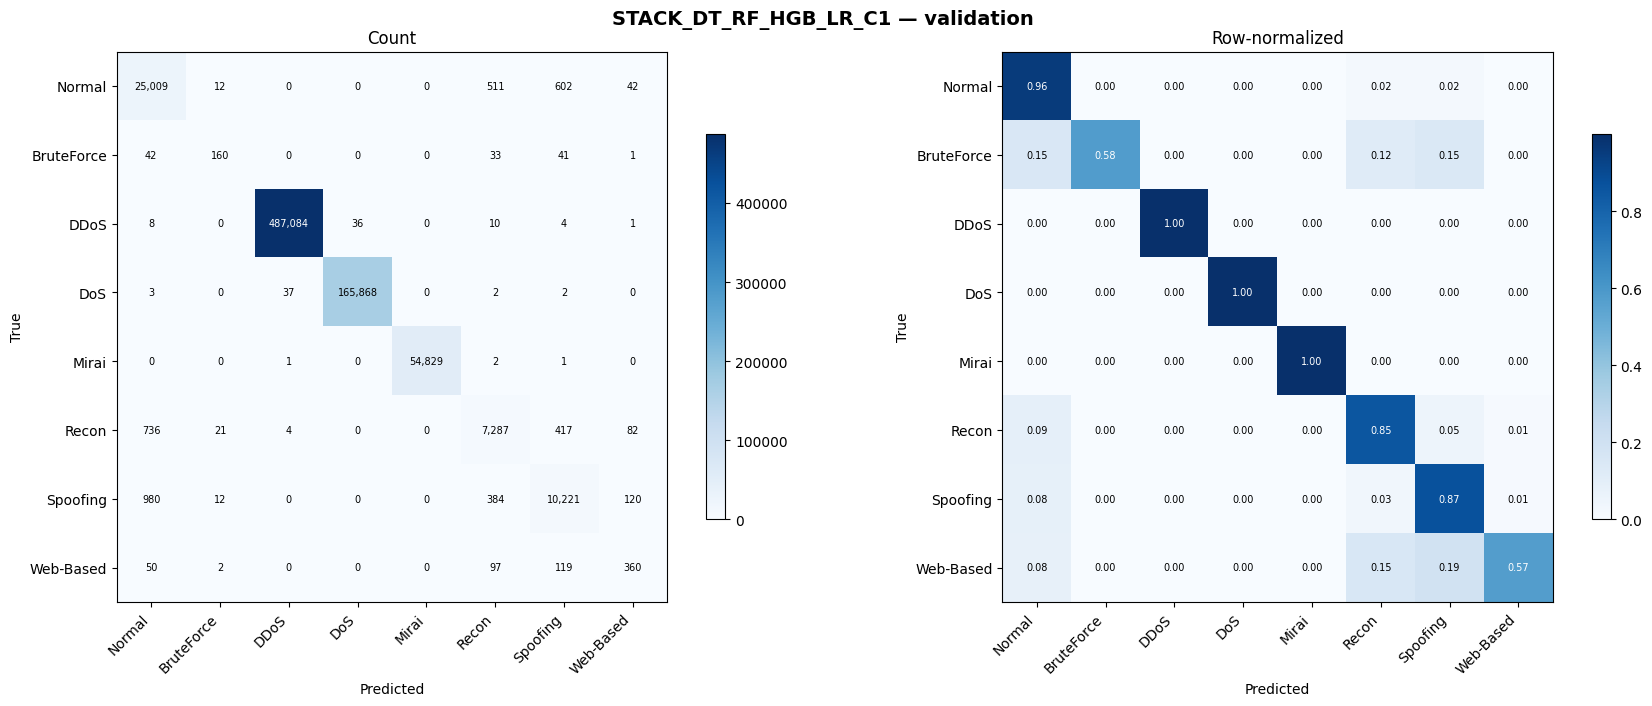


STACK_DT_RF_HGB_LR_C1 | VALIDATION
Macro-F1: 0.866959 | Accuracy: 0.994154
Prediction time: 0.26 s | New meta fit: 0.00 s
Inference scope: meta-only; reused cached base probabilities


,Class,precision,recall,f1-score,support
0,Normal,0.93220,0.95542,0.94366,26176.0
1,BruteForce,0.77295,0.57762,0.66116,277.0
2,DDoS,0.99991,0.99988,0.99990,487143.0
3,DoS,0.99978,0.99973,0.99976,165912.0
4,Mirai,1.00000,0.99993,0.99996,54833.0
5,Recon,0.87521,0.85258,0.86375,8547.0
6,Spoofing,0.89603,0.87232,0.88402,11717.0
7,Web-Based,0.59406,0.57325,0.58347,628.0


[OK] Original validation macro-F1 reproduced: 0.866959


In [11]:
print("=" * 70)
print("REPRODUCE ORIGINAL LOGISTIC REGRESSION BASELINE")
print("=" * 70)

started = time.perf_counter()
baseline_val_probabilities = model_probabilities(source_bundle["meta_model"], meta_val)
baseline_predict_seconds = time.perf_counter() - started
baseline_macro_f1 = float(f1_score(
    y_val, baseline_val_probabilities.argmax(axis=1), labels=CLASS_IDS,
    average="macro", zero_division=0,
))
source_validation_table = pd.read_csv(STACKING_DIR / "validation_comparison.csv")
source_baseline_rows = source_validation_table.loc[source_validation_table["candidate_id"] == BASELINE_ID]
if len(source_baseline_rows) != 1:
    raise ValueError("Source validation table không có đúng một baseline row.")
expected_macro_f1 = float(baseline_record["validation_macro_f1"])
if not np.isclose(baseline_macro_f1, expected_macro_f1, rtol=0, atol=1e-12):
    raise ValueError("LR baseline không tái lập macro-F1 nguồn; cần kiểm tra data/base/class order.")
if not np.isclose(baseline_macro_f1, float(source_baseline_rows.iloc[0]["macro_f1"]), rtol=0, atol=1e-12):
    raise ValueError("LR baseline không khớp source validation comparison.")

metrics = evaluate_predictions(
    BASELINE_ID, "validation", y_val, baseline_val_probabilities,
    baseline_predict_seconds, 0.0, "meta-only; reused cached base probabilities",
)
metrics["kind"] = "baseline_lr"
metrics["is_baseline"] = True
validation_records = [metrics]
np.save(OUTPUT_DIR / "baseline_validation_probabilities.npy", baseline_val_probabilities, allow_pickle=False)
del baseline_val_probabilities
print(f"[OK] Original validation macro-F1 reproduced: {baseline_macro_f1:.6f}")

## 7. Train XGBoost Meta-Candidates on Existing OOF

Đây là phần duy nhất gọi `.fit()` trong notebook. Đầu vào luôn là OOF, nhãn luôn là y_train.
`rare_weight=2` chỉ tăng trọng số BruteForce/Web-Based lên 2, các lớp khác giữ 1; không dùng cân bằng nghịch tần suất cực lớn.
`mlogloss` là metric của XGBoost; lựa chọn cấu hình vẫn dựa trên macro-F1 validation.


TRAIN XGBOOST META-MODELS — REUSE ALL BASE MODELS


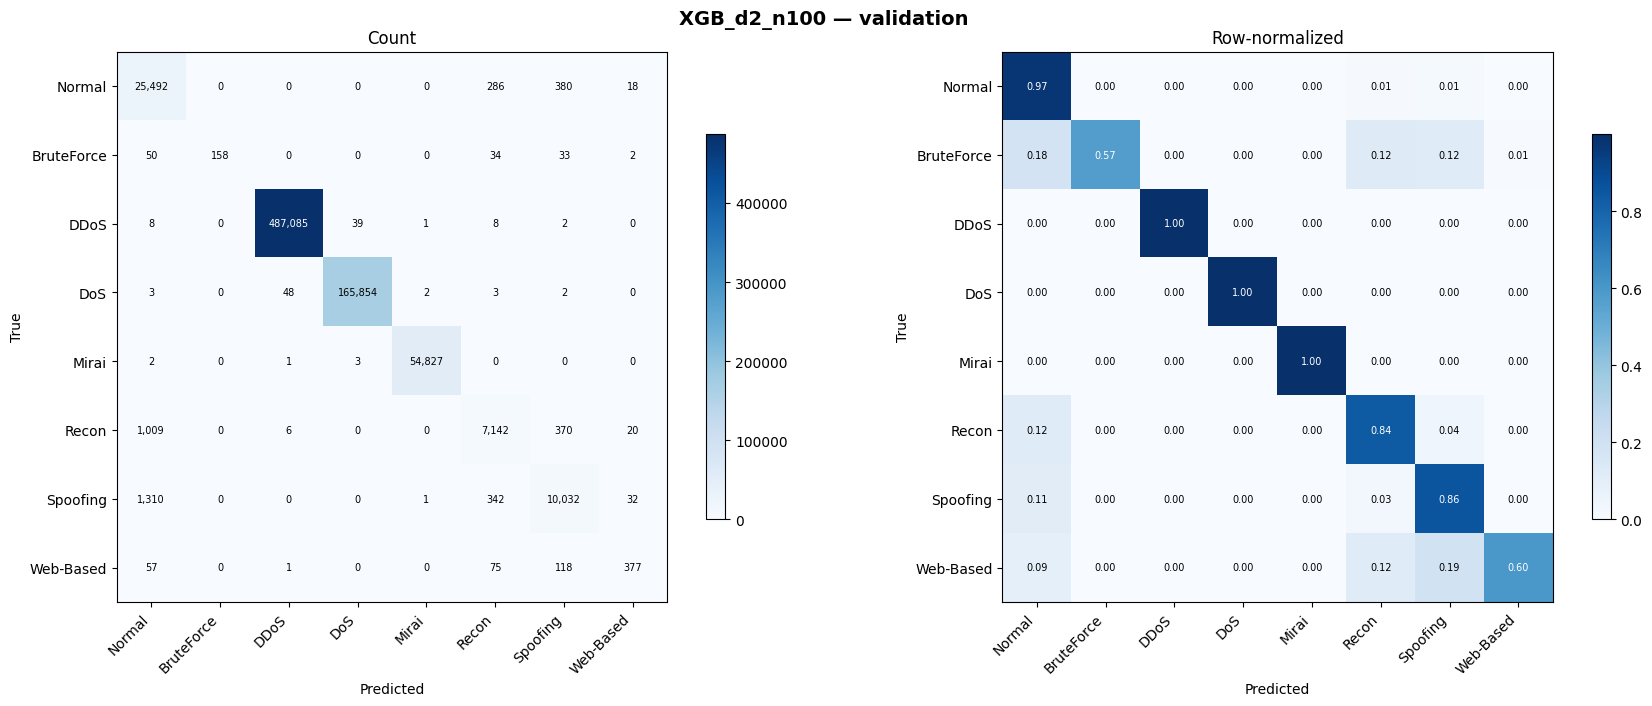


XGB_d2_n100 | VALIDATION
Macro-F1: 0.890373 | Accuracy: 0.994351
Prediction time: 2.56 s | New meta fit: 156.43 s
Inference scope: meta-only; reused cached base probabilities


,Class,precision,recall,f1-score,support
0,Normal,0.91268,0.97387,0.94228,26176.0
1,BruteForce,1.00000,0.57040,0.72644,277.0
2,DDoS,0.99989,0.99988,0.99988,487143.0
3,DoS,0.99975,0.99965,0.99970,165912.0
4,Mirai,0.99993,0.99989,0.99991,54833.0
5,Recon,0.90520,0.83561,0.86902,8547.0
6,Spoofing,0.91725,0.85619,0.88567,11717.0
7,Web-Based,0.83964,0.60032,0.70009,628.0


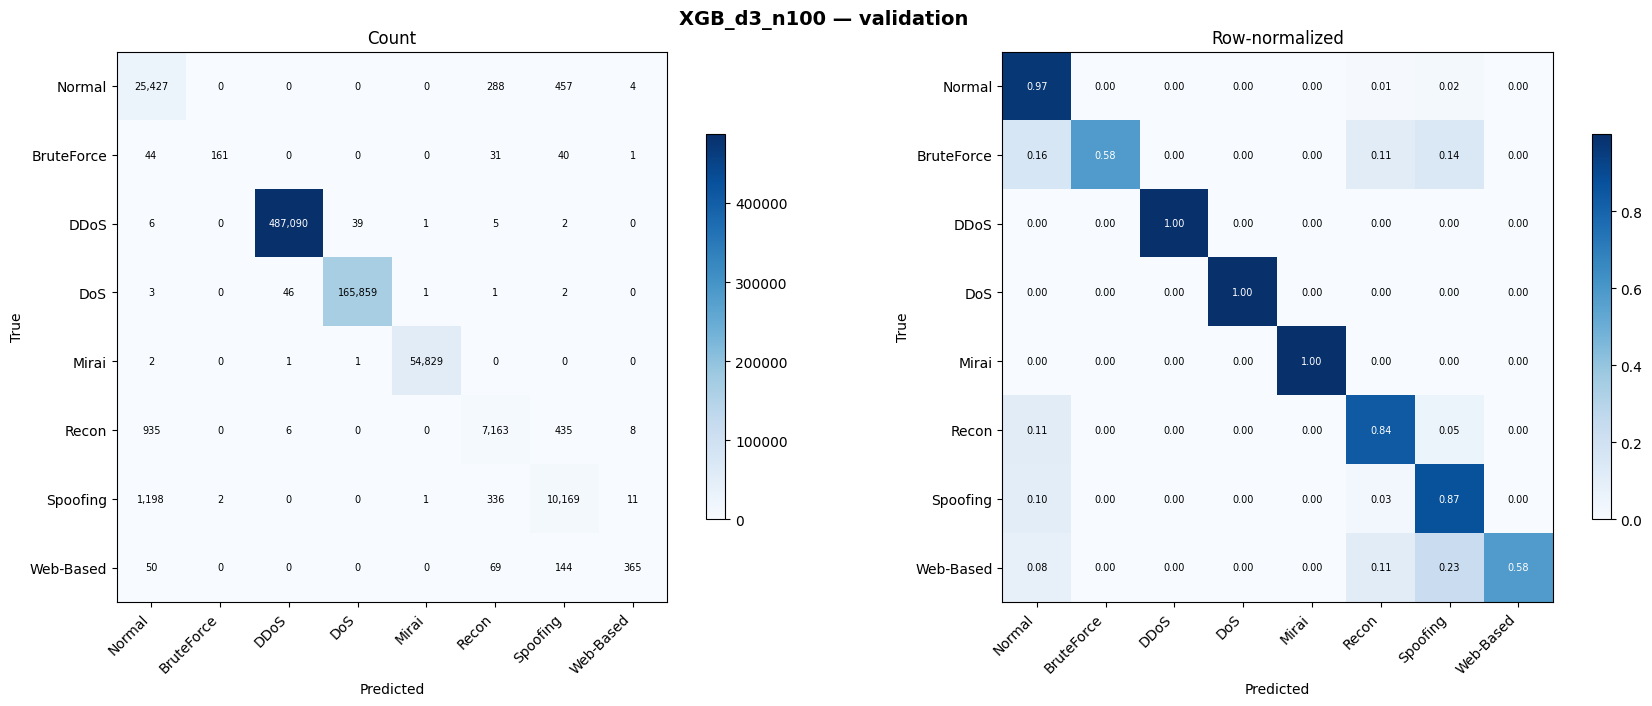


XGB_d3_n100 | VALIDATION
Macro-F1: 0.893833 | Accuracy: 0.994479
Prediction time: 3.65 s | New meta fit: 163.70 s
Inference scope: meta-only; reused cached base probabilities


,Class,precision,recall,f1-score,support
0,Normal,0.91910,0.97139,0.94452,26176.0
1,BruteForce,0.98773,0.58123,0.73182,277.0
2,DDoS,0.99989,0.99989,0.99989,487143.0
3,DoS,0.99976,0.99968,0.99972,165912.0
4,Mirai,0.99995,0.99993,0.99994,54833.0
5,Recon,0.90751,0.83807,0.87141,8547.0
6,Spoofing,0.90399,0.86788,0.88557,11717.0
7,Web-Based,0.93830,0.58121,0.71780,628.0


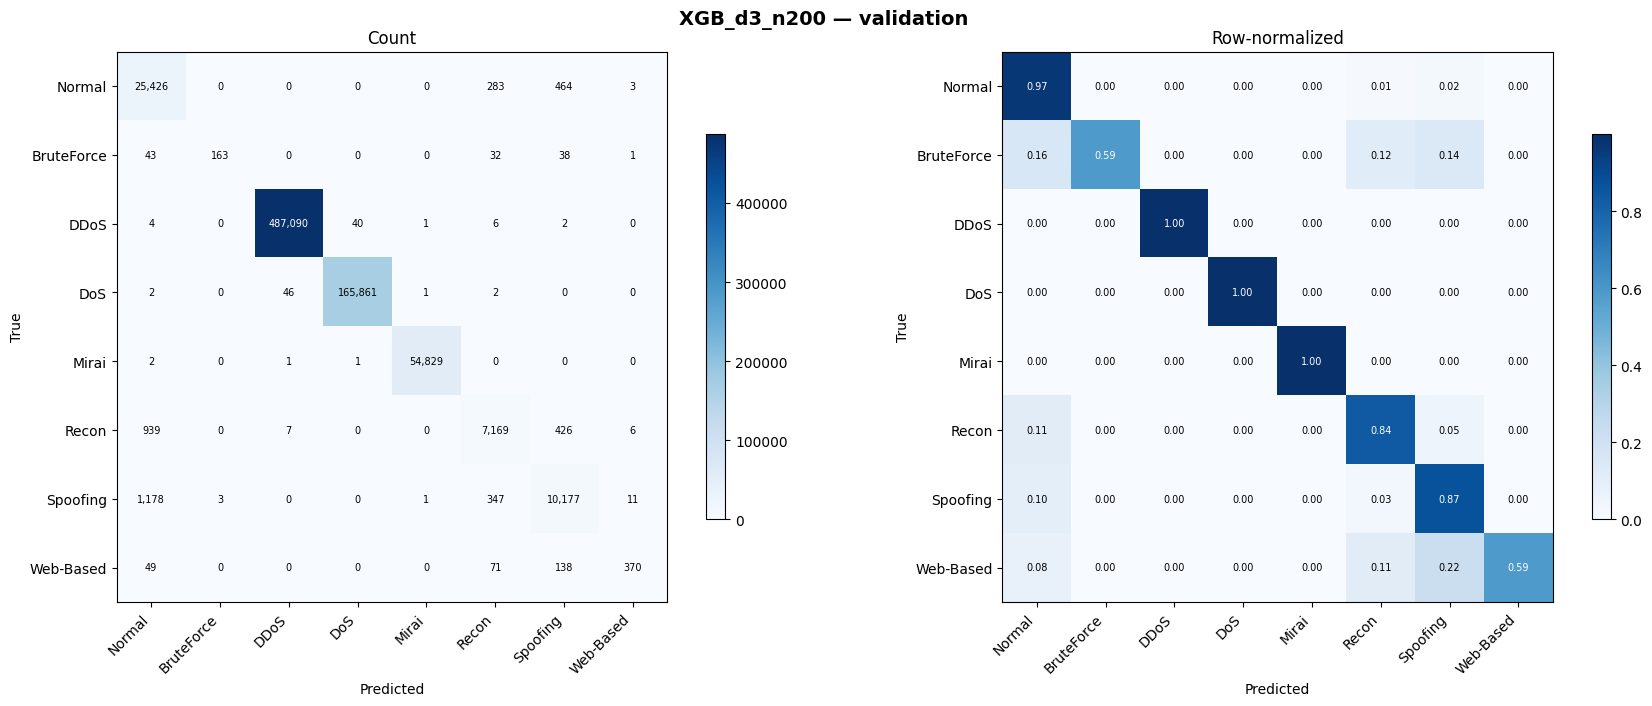


XGB_d3_n200 | VALIDATION
Macro-F1: 0.895522 | Accuracy: 0.994508
Prediction time: 7.07 s | New meta fit: 340.52 s
Inference scope: meta-only; reused cached base probabilities


,Class,precision,recall,f1-score,support
0,Normal,0.91980,0.97135,0.94487,26176.0
1,BruteForce,0.98193,0.58845,0.73589,277.0
2,DDoS,0.99989,0.99989,0.99989,487143.0
3,DoS,0.99975,0.99969,0.99972,165912.0
4,Mirai,0.99995,0.99993,0.99994,54833.0
5,Recon,0.90632,0.83877,0.87124,8547.0
6,Spoofing,0.90502,0.86857,0.88642,11717.0
7,Web-Based,0.94629,0.58917,0.72620,628.0


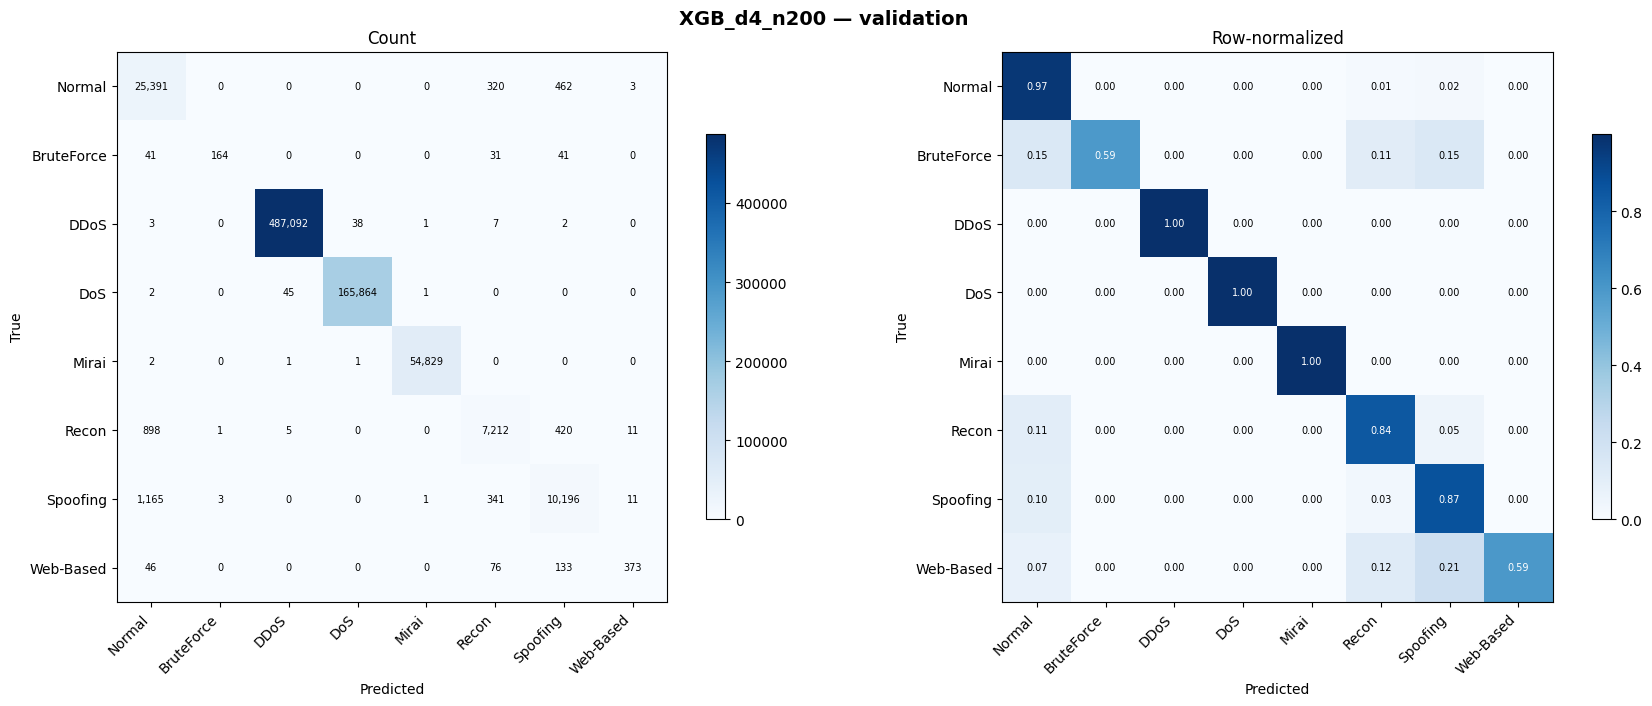


XGB_d4_n200 | VALIDATION
Macro-F1: 0.896137 | Accuracy: 0.994555
Prediction time: 8.81 s | New meta fit: 341.77 s
Inference scope: meta-only; reused cached base probabilities


,Class,precision,recall,f1-score,support
0,Normal,0.92170,0.97001,0.94524,26176.0
1,BruteForce,0.97619,0.59206,0.73708,277.0
2,DDoS,0.99990,0.99990,0.99990,487143.0
3,DoS,0.99976,0.99971,0.99974,165912.0
4,Mirai,0.99995,0.99993,0.99994,54833.0
5,Recon,0.90297,0.84380,0.87238,8547.0
6,Spoofing,0.90599,0.87019,0.88773,11717.0
7,Web-Based,0.93719,0.59395,0.72710,628.0


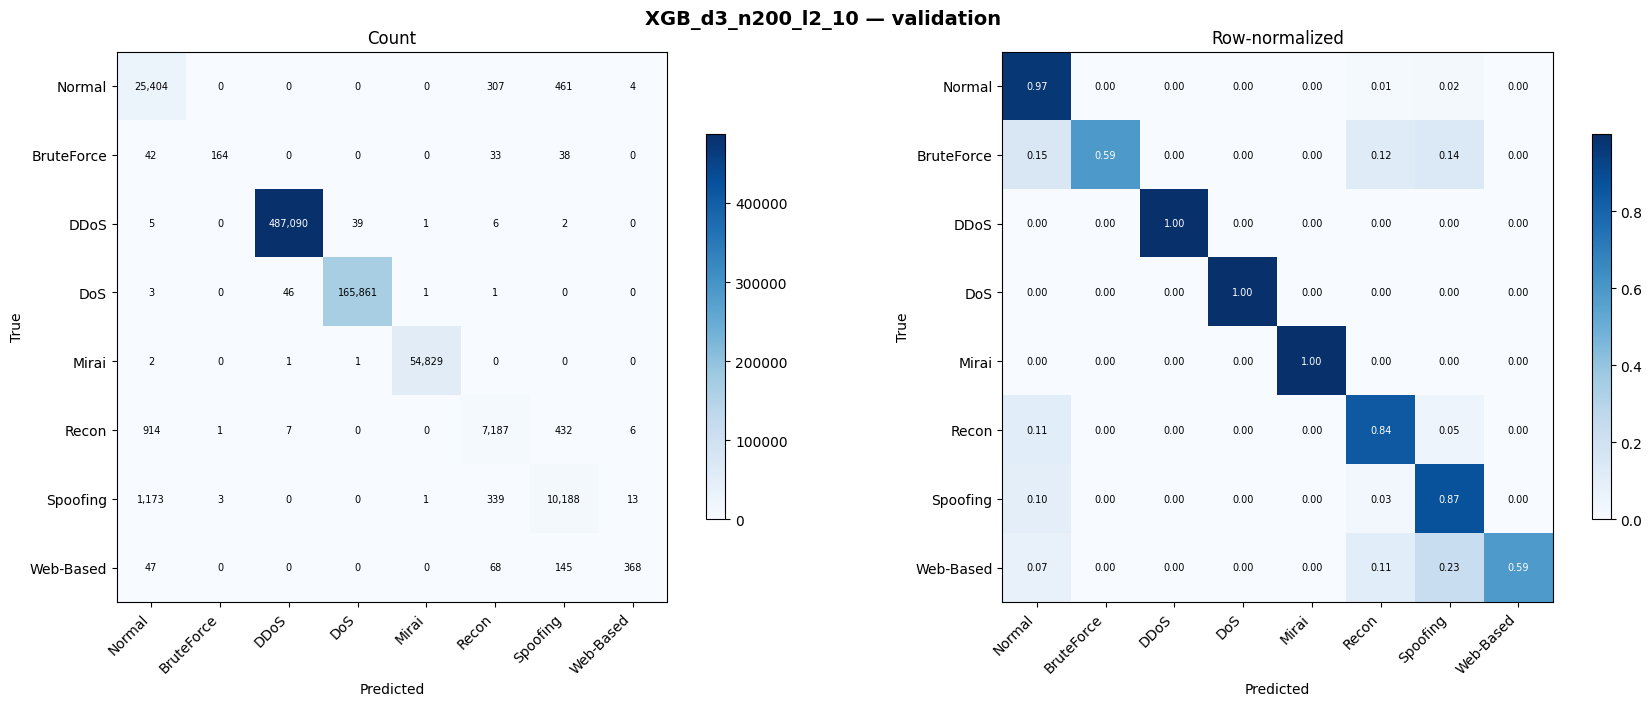


XGB_d3_n200_l2_10 | VALIDATION
Macro-F1: 0.895281 | Accuracy: 0.994516
Prediction time: 6.97 s | New meta fit: 326.39 s
Inference scope: meta-only; reused cached base probabilities


,Class,precision,recall,f1-score,support
0,Normal,0.92077,0.97051,0.94498,26176.0
1,BruteForce,0.97619,0.59206,0.73708,277.0
2,DDoS,0.99989,0.99989,0.99989,487143.0
3,DoS,0.99976,0.99969,0.99973,165912.0
4,Mirai,0.99995,0.99993,0.99994,54833.0
5,Recon,0.90505,0.84088,0.87179,8547.0
6,Spoofing,0.90431,0.86951,0.88657,11717.0
7,Web-Based,0.94118,0.58599,0.72228,628.0


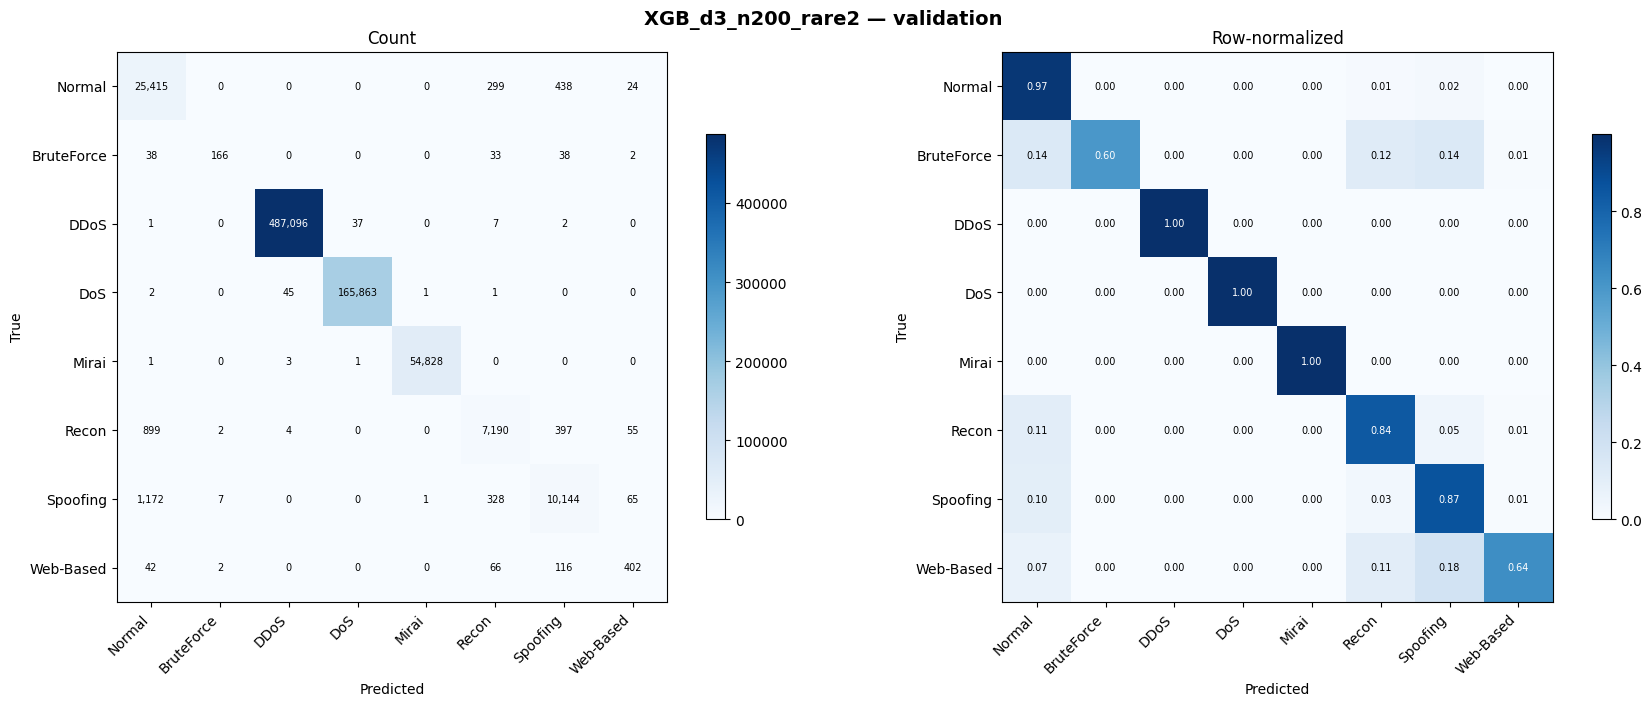


XGB_d3_n200_rare2 | VALIDATION
Macro-F1: 0.890140 | Accuracy: 0.994533
Prediction time: 6.99 s | New meta fit: 327.32 s
Inference scope: meta-only; reused cached base probabilities


,Class,precision,recall,f1-score,support
0,Normal,0.92184,0.97093,0.94574,26176.0
1,BruteForce,0.93785,0.59928,0.73128,277.0
2,DDoS,0.99989,0.99990,0.99990,487143.0
3,DoS,0.99977,0.99970,0.99974,165912.0
4,Mirai,0.99996,0.99991,0.99994,54833.0
5,Recon,0.90737,0.84123,0.87305,8547.0
6,Spoofing,0.91100,0.86575,0.88780,11717.0
7,Web-Based,0.73358,0.64013,0.68367,628.0



VALIDATION COMPARISON — NEW XGBOOST VS ORIGINAL LR:


,candidate_id,split,accuracy,macro_f1,weighted_f1,meta_fit_seconds_this_run,predict_seconds,inference_scope,rows,predict_ms_per_row,kind,is_baseline
0,XGB_d4_n200,validation,0.994555,0.896137,0.994463,341.771302,8.807458,meta-only; reused cached base probabilities,755233,0.011662,xgboost_meta,False
1,XGB_d3_n200,validation,0.994508,0.895522,0.994409,340.516469,7.069499,meta-only; reused cached base probabilities,755233,0.009361,xgboost_meta,False
2,XGB_d3_n200_l2_10,validation,0.994516,0.895281,0.994419,326.387080,6.968401,meta-only; reused cached base probabilities,755233,0.009227,xgboost_meta,False
3,XGB_d3_n100,validation,0.994479,0.893833,0.994377,163.697489,3.651481,meta-only; reused cached base probabilities,755233,0.004835,xgboost_meta,False
4,XGB_d2_n100,validation,0.994351,0.890373,0.994245,156.430082,2.564993,meta-only; reused cached base probabilities,755233,0.003396,xgboost_meta,False
5,XGB_d3_n200_rare2,validation,0.994533,0.890140,0.994453,327.322610,6.988706,meta-only; reused cached base probabilities,755233,0.009254,xgboost_meta,False
6,STACK_DT_RF_HGB_LR_C1,validation,0.994154,0.866959,0.994113,0.000000,0.259821,meta-only; reused cached base probabilities,755233,0.000344,baseline_lr,True


All validation timing above is meta-only; end-to-end timing is measured after freeze.


In [12]:
print("=" * 70)
print("TRAIN XGBOOST META-MODELS — REUSE ALL BASE MODELS")
print("=" * 70)

META_MODEL_DIR = OUTPUT_DIR / "meta_models"
META_MODEL_DIR.mkdir()
candidate_details = {}
meta_training_records = []
for config in XGB_CONFIGS:
    candidate_id = config["name"]
    parameters = XGB_COMMON_PARAMS.copy()
    parameters["max_depth"] = config["max_depth"]
    parameters["n_estimators"] = config["n_estimators"]
    parameters["reg_lambda"] = config["reg_lambda"]
    model = XGBClassifier(**parameters)

    sample_weights = None
    if config["rare_weight"] != 1.0:
        sample_weights = np.ones(len(y_train), dtype=np.float32)
        sample_weights[(y_train == 1) | (y_train == 7)] = config["rare_weight"]

    started = time.perf_counter()
    with threadpool_limits(limits=N_JOBS):
        model.fit(meta_train, y_train, sample_weight=sample_weights, verbose=False)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    probabilities = model_probabilities(model, meta_val)
    predict_seconds = time.perf_counter() - started

    model_path = META_MODEL_DIR / f"{candidate_id}.json"
    model.save_model(model_path)
    probability_path = OUTPUT_DIR / f"validation_{candidate_id}_probabilities.npy"
    np.save(probability_path, probabilities, allow_pickle=False)
    metrics = evaluate_predictions(
        candidate_id, "validation", y_val, probabilities,
        predict_seconds, fit_seconds, "meta-only; reused cached base probabilities",
    )
    metrics["kind"] = "xgboost_meta"
    metrics["is_baseline"] = False
    validation_records.append(metrics)
    candidate_details[candidate_id] = {
        "parameters": parameters, "rare_weight": config["rare_weight"],
        "meta_fit_seconds": fit_seconds, "model_file": str(model_path.relative_to(OUTPUT_DIR)),
        "model_sha256": sha256_file(model_path),
        "validation_probabilities_file": probability_path.name,
    }
    meta_training_records.append({
        "candidate_id": candidate_id, "meta_fit_seconds": fit_seconds,
        "validation_meta_predict_seconds": predict_seconds, "base_fit_seconds_this_run": 0.0,
    })
    pd.DataFrame(meta_training_records).to_csv(OUTPUT_DIR / "meta_training_times.csv", index=False)
    write_json(OUTPUT_DIR / "candidate_details.json", candidate_details)
    del model, probabilities, sample_weights
    gc.collect()

validation_table = pd.DataFrame(validation_records).sort_values(
    ["macro_f1", "is_baseline", "candidate_id"],
    ascending=[False, False, True], kind="stable",
).reset_index(drop=True)
validation_table.to_csv(OUTPUT_DIR / "validation_comparison.csv", index=False)
print("\nVALIDATION COMPARISON — NEW XGBOOST VS ORIGINAL LR:")
display(validation_table.round(6))
print("All validation timing above is meta-only; end-to-end timing is measured after freeze.")

## 8. Freeze Best XGBoost and Original LR Before Test

Xuất bundle tự chứa preprocessor + ba base models đã có + meta-model mới.
Lưu thêm model XGBoost native JSON; giữ nguyên bundle LR làm đối chứng, không thay đổi source artifacts.
Ứng viên chính được chốt bằng validation, kể cả khi LR tiếp tục tốt nhất.


In [13]:
print("=" * 70)
print("FREEZE CANDIDATES BEFORE REUSED TEST COMPARISON")
print("=" * 70)

best_xgb_row = validation_table.loc[validation_table["kind"] == "xgboost_meta"].iloc[0]
BEST_XGB_ID = best_xgb_row["candidate_id"]
PRIMARY_ID = validation_table.iloc[0]["candidate_id"]
best_details = candidate_details[BEST_XGB_ID]
if sha256_file(OUTPUT_DIR / best_details["model_file"]) != best_details["model_sha256"]:
    raise RuntimeError("Best meta model file thay đổi sau validation.")
best_meta_model = XGBClassifier(n_jobs=N_JOBS)
best_meta_model.load_model(OUTPUT_DIR / best_details["model_file"])

# Kiểm chứng native JSON reload trên validation so với model trong lúc train.
reloaded_probabilities = model_probabilities(best_meta_model, meta_val)
saved_probabilities = np.load(
    OUTPUT_DIR / best_details["validation_probabilities_file"], mmap_mode="r", allow_pickle=False
)
np.testing.assert_allclose(reloaded_probabilities, saved_probabilities, rtol=1e-6, atol=1e-7)
np.testing.assert_array_equal(reloaded_probabilities.argmax(axis=1), saved_probabilities.argmax(axis=1))

FROZEN_DIR = OUTPUT_DIR / "frozen_models"
FROZEN_DIR.mkdir()
new_bundle = source_bundle.copy()
new_bundle.update({
    "protocol": PROTOCOL, "candidate_id": BEST_XGB_ID,
    "meta_model": best_meta_model, "versions": versions,
    "source_stacking_run_id": SOURCE_RUN_ID,
    "meta_feature_names": meta_feature_names, "threads": N_JOBS,
})
xgb_bundle_path = FROZEN_DIR / f"{BEST_XGB_ID}.joblib"
joblib.dump(new_bundle, xgb_bundle_path)
selected_native_path = FROZEN_DIR / f"{BEST_XGB_ID}.json"
best_meta_model.save_model(selected_native_path)
write_json(FROZEN_DIR / "selected_xgb_parameters.json", best_details)

# Copy baseline nguyên trạng vào output mới để gói bàn giao không phụ thuộc source folder.
lr_bundle_path = FROZEN_DIR / f"{BASELINE_ID}.joblib"
shutil.copyfile(baseline_path, lr_bundle_path)
if sha256_file(lr_bundle_path) != baseline_record["sha256"]:
    raise RuntimeError("Baseline bundle copy không khớp nguồn.")

frozen_candidates = []
for candidate_id, kind, path in [
    (BEST_XGB_ID, "xgboost_meta", xgb_bundle_path),
    (BASELINE_ID, "baseline_lr", lr_bundle_path),
]:
    row = validation_table.loc[validation_table["candidate_id"] == candidate_id].iloc[0]
    frozen_candidates.append({
        "candidate_id": candidate_id, "kind": kind,
        "bundle_file": str(path.relative_to(OUTPUT_DIR)), "sha256": sha256_file(path),
        "validation_macro_f1": float(row["macro_f1"]),
        "meta_fit_seconds_this_run": float(row["meta_fit_seconds_this_run"]),
    })
freeze_record = {
    "run_id": RUN_ID, "source_stacking_run_id": SOURCE_RUN_ID, "data_run_id": DATA_RUN_ID,
    "primary_candidate_id": PRIMARY_ID, "candidates": frozen_candidates,
    "protocol_sha256": sha256_file(OUTPUT_DIR / "protocol.json"),
    "source_artifacts_sha256": sha256_file(OUTPUT_DIR / "source_artifacts.json"),
    "validation_table_sha256": sha256_file(OUTPUT_DIR / "validation_comparison.csv"),
    "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "test_previously_viewed": True,
}
write_json(OUTPUT_DIR / "frozen_candidates.json", freeze_record)
print(f"Best XGBoost: {BEST_XGB_ID}")
print(f"Original LR : {BASELINE_ID}")
print(f"Primary     : {PRIMARY_ID} (chosen on validation)")
print(f"Validation macro-F1 delta (XGB - LR): {float(best_xgb_row['macro_f1']) - baseline_macro_f1:+.6f}")
del source_bundle, new_bundle, best_meta_model, reloaded_probabilities, saved_probabilities
# Giải phóng cache OOF; sau freeze chỉ nạp bundle đã chốt để suy luận.
del meta_train
gc.collect()
print("[OK] Candidates and provenance frozen; no X_test/y_test loaded yet.")

FREEZE CANDIDATES BEFORE REUSED TEST COMPARISON
Best XGBoost: XGB_d4_n200
Original LR : STACK_DT_RF_HGB_LR_C1
Primary     : XGB_d4_n200 (chosen on validation)
Validation macro-F1 delta (XGB - LR): +0.029178
[OK] Candidates and provenance frozen; no X_test/y_test loaded yet.


## 9. Export Standalone Prediction Code and Run Golden CSV Checks

Bộ suy luận dùng cùng tiền xử lý và thứ tự DT → RF → HGB như source run.
Golden samples lấy tối đa 4 dòng đầu của mỗi lớp validation (mặc định 32 dòng), không lấy test.
Đối chiếu bundle sau reload với xác suất đã dùng chọn cấu hình, rồi kiểm tra CSV round-trip.


In [14]:
inference_source = r'''

import argparse
import csv
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from threadpoolctl import threadpool_limits


def load_bundle(path):
    bundle = joblib.load(path)
    current_versions = {
        "numpy": np.__version__, "pandas": pd.__version__,
        "sklearn": sklearn.__version__, "joblib": joblib.__version__,
    }
    if "xgboost" in bundle["versions"]:
        import xgboost
        current_versions["xgboost"] = xgboost.__version__
    for package, version in current_versions.items():
        if bundle["versions"][package] != version:
            raise RuntimeError(f"Use recorded {package} version: {bundle['versions'][package]}")
    return bundle


def read_csv_features(path, feature_names):
    with Path(path).open(newline="", encoding="utf-8-sig") as file:
        header = next(csv.reader(file))
    if len(header) != len(set(header)):
        raise ValueError("CSV has duplicate column names.")
    data = pd.read_csv(path)
    missing = sorted(set(feature_names) - set(data.columns))
    extra = sorted(set(data.columns) - set(feature_names) - {"label"})
    if missing or extra or len(data.columns) != len(set(data.columns)):
        raise ValueError(f"CSV schema mismatch: missing={missing}, extra={extra}")
    features = data.loc[:, feature_names].astype(np.float64)
    features = features.replace([np.inf, -np.inf], np.nan)
    with np.errstate(over="ignore", invalid="ignore"):
        values = features.to_numpy(dtype=np.float32)
    if np.isinf(values).any():
        raise ValueError("Float32 conversion overflowed.")
    return values


def predict_bundle(bundle, values, batch_size=25000):
    if values.ndim != 2 or values.shape[1] != len(bundle["feature_names"]):
        raise ValueError("Unexpected input feature count/order.")
    expected_classes = np.arange(len(bundle["class_names"]))
    result = np.empty((len(values), len(expected_classes)), dtype=np.float32)
    with threadpool_limits(limits=bundle["threads"]):
        for start in range(0, len(values), batch_size):
            stop = min(start + batch_size, len(values))
            with np.errstate(over="ignore", invalid="ignore"):
                batch = np.asarray(values[start:stop], dtype=np.float32)
            if np.isinf(batch).any():
                raise ValueError("Input has Inf or float32 overflow.")
            transformed = bundle["preprocessor"].transform(batch).astype(np.float32, copy=False)
            if not np.isfinite(transformed).all():
                raise ValueError("Preprocessing produced NaN/Inf.")
            blocks = []
            for name in bundle["base_names"]:
                model = bundle["base_models"][name]
                if not np.array_equal(model.classes_, expected_classes):
                    raise ValueError("Unexpected base class order.")
                probabilities = model.predict_proba(transformed).astype(np.float32)
                blocks.append(probabilities)
            if bundle["kind"] == "base":
                probabilities = blocks[0]
            else:
                meta_input = np.concatenate(blocks, axis=1)
                model = bundle["meta_model"]
                if not np.array_equal(model.classes_, expected_classes):
                    raise ValueError("Unexpected meta class order.")
                probabilities = model.predict_proba(meta_input).astype(np.float32)
            if not np.isfinite(probabilities).all():
                raise ValueError("Non-finite probabilities.")
            if np.any(probabilities < 0) or np.any(probabilities > 1):
                raise ValueError("Probabilities outside [0, 1].")
            if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5):
                raise ValueError("Probabilities do not sum to one.")
            result[start:stop] = probabilities
    return result


def predict_csv(bundle_path, input_path, output_path):
    bundle = load_bundle(bundle_path)
    values = read_csv_features(input_path, bundle["feature_names"])
    probabilities = predict_bundle(bundle, values)
    predicted = probabilities.argmax(axis=1)
    output = pd.DataFrame({"class_id": predicted})
    output["class_name"] = np.asarray(bundle["class_names"])[predicted]
    for class_id, class_name in enumerate(bundle["class_names"]):
        output[f"prob_{class_name}"] = probabilities[:, class_id]
    output.to_csv(output_path, index=False)
    return output


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--bundle", required=True, type=Path)
    parser.add_argument("--input", required=True, type=Path)
    parser.add_argument("--output", required=True, type=Path)
    args = parser.parse_args()
    predict_csv(args.bundle, args.input, args.output)
'''

predict_script = OUTPUT_DIR / "predict_csv.py"
predict_script.write_text(inference_source, encoding="utf-8")
spec = importlib.util.spec_from_file_location("xgb_meta_csv_prediction", predict_script)
prediction_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(prediction_module)
print(f"Prediction helper saved to: {predict_script}")

Prediction helper saved to: /kaggle/working/stacking_meta_runs/xgb_meta_20261021_092334_9024562d/predict_csv.py


In [15]:
print("=" * 70)
print("RELOAD AND GOLDEN CSV CHECKS — VALIDATION ONLY")
print("=" * 70)

if GOLDEN_SAMPLE_SIZE < len(CLASS_NAMES):
    raise ValueError("GOLDEN_SAMPLE_SIZE cần ít nhất 8 để có đủ lớp.")
golden_indices = []
rows_per_class = GOLDEN_SAMPLE_SIZE // len(CLASS_NAMES)
for class_id in CLASS_IDS:
    indices = np.flatnonzero(y_val == class_id)[:rows_per_class]
    golden_indices.extend(indices.tolist())
golden_indices = np.asarray(golden_indices, dtype=np.int64)
golden_values = np.array(X_val[golden_indices], copy=True)
GOLDEN_DIR = OUTPUT_DIR / "golden_samples"
GOLDEN_DIR.mkdir()
golden_csv = GOLDEN_DIR / "input.csv"
pd.DataFrame(golden_values, columns=feature_names).to_csv(golden_csv, index=False, float_format="%.17g")
golden_from_csv = prediction_module.read_csv_features(golden_csv, feature_names)
np.testing.assert_allclose(golden_values, golden_from_csv, rtol=0, atol=0, equal_nan=True)

val_metadata = pd.read_pickle(DATA_DIR / "sample_metadata_val.pkl")
if len(val_metadata) != len(y_val):
    raise ValueError("Validation metadata lệch số dòng.")
np.testing.assert_array_equal(val_metadata["class_id"].to_numpy(), y_val)
val_metadata.iloc[golden_indices].to_csv(GOLDEN_DIR / "source_metadata.csv", index=False)
del val_metadata

reload_records = []
for selected in frozen_candidates:
    path = OUTPUT_DIR / selected["bundle_file"]
    if sha256_file(path) != selected["sha256"]:
        raise RuntimeError("Bundle thay đổi sau freeze.")
    if selected["kind"] == "baseline_lr":
        reference_file = OUTPUT_DIR / "baseline_validation_probabilities.npy"
    else:
        reference_file = OUTPUT_DIR / candidate_details[selected["candidate_id"]]["validation_probabilities_file"]
    reference = np.load(reference_file, mmap_mode="r", allow_pickle=False)[golden_indices]
    bundle = prediction_module.load_bundle(path)
    actual = prediction_module.predict_bundle(bundle, golden_values, BATCH_SIZE)
    np.testing.assert_allclose(actual, reference, rtol=1e-6, atol=1e-7)
    np.testing.assert_array_equal(actual.argmax(axis=1), reference.argmax(axis=1))

    output_csv = GOLDEN_DIR / f"{selected['candidate_id']}_predictions.csv"
    del bundle
    gc.collect()
    csv_output = prediction_module.predict_csv(path, golden_csv, output_csv)
    probability_columns = []
    for class_name in CLASS_NAMES:
        probability_columns.append(f"prob_{class_name}")
    np.testing.assert_allclose(csv_output[probability_columns].to_numpy(), reference, rtol=1e-6, atol=1e-7)
    np.testing.assert_array_equal(csv_output["class_id"].to_numpy(), reference.argmax(axis=1))
    reload_records.append({"candidate_id": selected["candidate_id"], "rows": len(golden_values), "passed": True})
    print(f"[OK] {selected['candidate_id']}: bundle reload, raw validation and CSV predictions match")
    del actual, reference, csv_output
    gc.collect()
write_json(OUTPUT_DIR / "reload_checks.json", reload_records)

RELOAD AND GOLDEN CSV CHECKS — VALIDATION ONLY
[OK] XGB_d4_n200: bundle reload, raw validation and CSV predictions match
[OK] STACK_DT_RF_HGB_LR_C1: bundle reload, raw validation and CSV predictions match


## 10. End-to-End Validation Benchmark of Frozen Bundles

Đo transform + ba base predictions + meta prediction. Không gồm load bundle, ghi báo cáo hoặc vẽ.
Đối chiếu toàn bộ xác suất với kết quả từ cached base probabilities; không chọn lại model sau freeze.


In [16]:
end_to_end_records = []
for selected in frozen_candidates:
    bundle = prediction_module.load_bundle(OUTPUT_DIR / selected["bundle_file"])
    started = time.perf_counter()
    probabilities = prediction_module.predict_bundle(bundle, X_val, BATCH_SIZE)
    elapsed = time.perf_counter() - started
    if selected["kind"] == "baseline_lr":
        reference_file = OUTPUT_DIR / "baseline_validation_probabilities.npy"
    else:
        reference_file = OUTPUT_DIR / candidate_details[selected["candidate_id"]]["validation_probabilities_file"]
    expected = np.load(reference_file, mmap_mode="r", allow_pickle=False)
    for start in range(0, len(y_val), BATCH_SIZE):
        stop = min(start + BATCH_SIZE, len(y_val))
        np.testing.assert_allclose(probabilities[start:stop], expected[start:stop], rtol=1e-6, atol=1e-7)
    np.testing.assert_array_equal(probabilities.argmax(axis=1), expected.argmax(axis=1))
    score = float(f1_score(y_val, probabilities.argmax(axis=1), labels=CLASS_IDS, average="macro", zero_division=0))
    if not np.isclose(score, selected["validation_macro_f1"], rtol=0, atol=1e-12):
        raise RuntimeError("Frozen bundle không tái lập validation macro-F1.")
    end_to_end_records.append({
        "candidate_id": selected["candidate_id"], "rows": len(y_val),
        "predict_seconds": elapsed, "predict_ms_per_row": elapsed / len(y_val) * 1000,
        "macro_f1": score, "scope": "raw input -> preprocessor -> bases -> meta",
    })
    del bundle, probabilities, expected
    gc.collect()
pd.DataFrame(end_to_end_records).to_csv(OUTPUT_DIR / "validation_end_to_end_timing.csv", index=False)
print("END-TO-END VALIDATION TIMING:")
display(pd.DataFrame(end_to_end_records).round(6))

END-TO-END VALIDATION TIMING:


,candidate_id,rows,predict_seconds,predict_ms_per_row,macro_f1,scope
0,XGB_d4_n200,755233,40.064738,0.053050,0.896137,raw input -> preprocessor -> bases -> meta
1,STACK_DT_RF_HGB_LR_C1,755233,31.964397,0.042324,0.866959,raw input -> preprocessor -> bases -> meta


## 11. Reused Test Comparison — Candidates Already Frozen

X_test/y_test được nạp lần đầu trong notebook này tại đây. **Run cũ đã đánh giá test này**, vì vậy đây là so sánh tiếp trên test đã dùng.
Không dùng kết quả test để đổi tham số hoặc đổi ứng viên chính. Các base/preprocessor giữ nguyên nên dùng lại reference hashes nguồn,
đồng thời kiểm tra lại input thực của test trước tính metric.


In [17]:
print("=" * 70)
print("REUSED TEST COMPARISON — NOT A NEW INDEPENDENT TEST")
print("=" * 70)

frozen = json.loads((OUTPUT_DIR / "frozen_candidates.json").read_text())
for file_name, checksum_key in [
    ("protocol.json", "protocol_sha256"),
    ("source_artifacts.json", "source_artifacts_sha256"),
    ("validation_comparison.csv", "validation_table_sha256"),
]:
    if sha256_file(OUTPUT_DIR / file_name) != frozen[checksum_key]:
        raise RuntimeError(f"{file_name} thay đổi sau freeze.")
if (OUTPUT_DIR / "test_evaluation_started.json").exists():
    raise RuntimeError("Run này đã bắt đầu đánh giá test; không lặp lại để chọn cấu hình.")
for selected in frozen["candidates"]:
    if sha256_file(OUTPUT_DIR / selected["bundle_file"]) != selected["sha256"]:
        raise RuntimeError("Frozen bundle checksum không khớp.")

X_test = np.load(DATA_DIR / "X_test_unprocessed.npy", mmap_mode="r", allow_pickle=False)
y_test = np.load(DATA_DIR / "y_test.npy", allow_pickle=False)
if X_test.dtype != np.float32 or X_test.shape != (len(y_test), len(feature_names)):
    raise ValueError("Test schema/dtype không khớp.")
if list(X_test.shape) != data_config["artifacts"]["test"]["shape"]:
    raise ValueError("Test shape khác processing config.")
check_classes(y_test, "test")

# Tái kiểm tra đúng vector float32 sau source preprocessor; không có fit ở đây.
bundle = prediction_module.load_bundle(OUTPUT_DIR / frozen["candidates"][0]["bundle_file"])
test_hashes = np.empty(len(X_test), dtype="V16")
for start in range(0, len(X_test), BATCH_SIZE):
    stop = min(start + BATCH_SIZE, len(X_test))
    batch = np.asarray(X_test[start:stop], dtype=np.float32)
    if np.isinf(batch).any():
        raise ValueError("Test input chứa Inf.")
    transformed = bundle["preprocessor"].transform(batch).astype(np.float32, copy=False)
    if not np.isfinite(transformed).all():
        raise ValueError("Test sau tiền xử lý chứa NaN/Inf.")
    transformed = np.array(transformed, dtype="<f4", order="C", copy=True)
    transformed[transformed == 0] = 0.0
    hashes = []
    for row in transformed:
        hashes.append(hashlib.blake2b(row.tobytes(), digest_size=16).digest())
    test_hashes[start:stop] = np.asarray(hashes, dtype="V16")
unique_test_hashes = np.unique(test_hashes)
test_overlap_records = []
for file_name in ["full_train_input_hashes.npy", "val_input_hashes.npy"]:
    path = STACKING_DIR / file_name
    recorded = next(item for item in source_files if item["path"] == str(path))
    if sha256_file(path) != recorded["sha256"]:
        raise RuntimeError("Source reference hashes thay đổi sau ghi nhận provenance.")
    reference = np.load(path, mmap_mode="r", allow_pickle=False)
    overlap_count = int(len(np.intersect1d(reference, unique_test_hashes, assume_unique=True)))
    if overlap_count > 0:
        raise ValueError(f"Test input trùng {overlap_count} nhóm với {file_name}.")
    test_overlap_records.append({"reference": file_name, "overlap_groups": 0})
write_json(OUTPUT_DIR / "test_effective_overlap_audit.json", test_overlap_records)
del bundle, batch, transformed, hashes, test_hashes, unique_test_hashes, reference

write_json(OUTPUT_DIR / "test_evaluation_started.json", {
    "frozen_candidates_sha256": sha256_file(OUTPUT_DIR / "frozen_candidates.json"),
    "started_at": time.strftime("%Y-%m-%d %H:%M:%S"), "test_previously_viewed": True,
})

REUSED TEST COMPARISON — NOT A NEW INDEPENDENT TEST


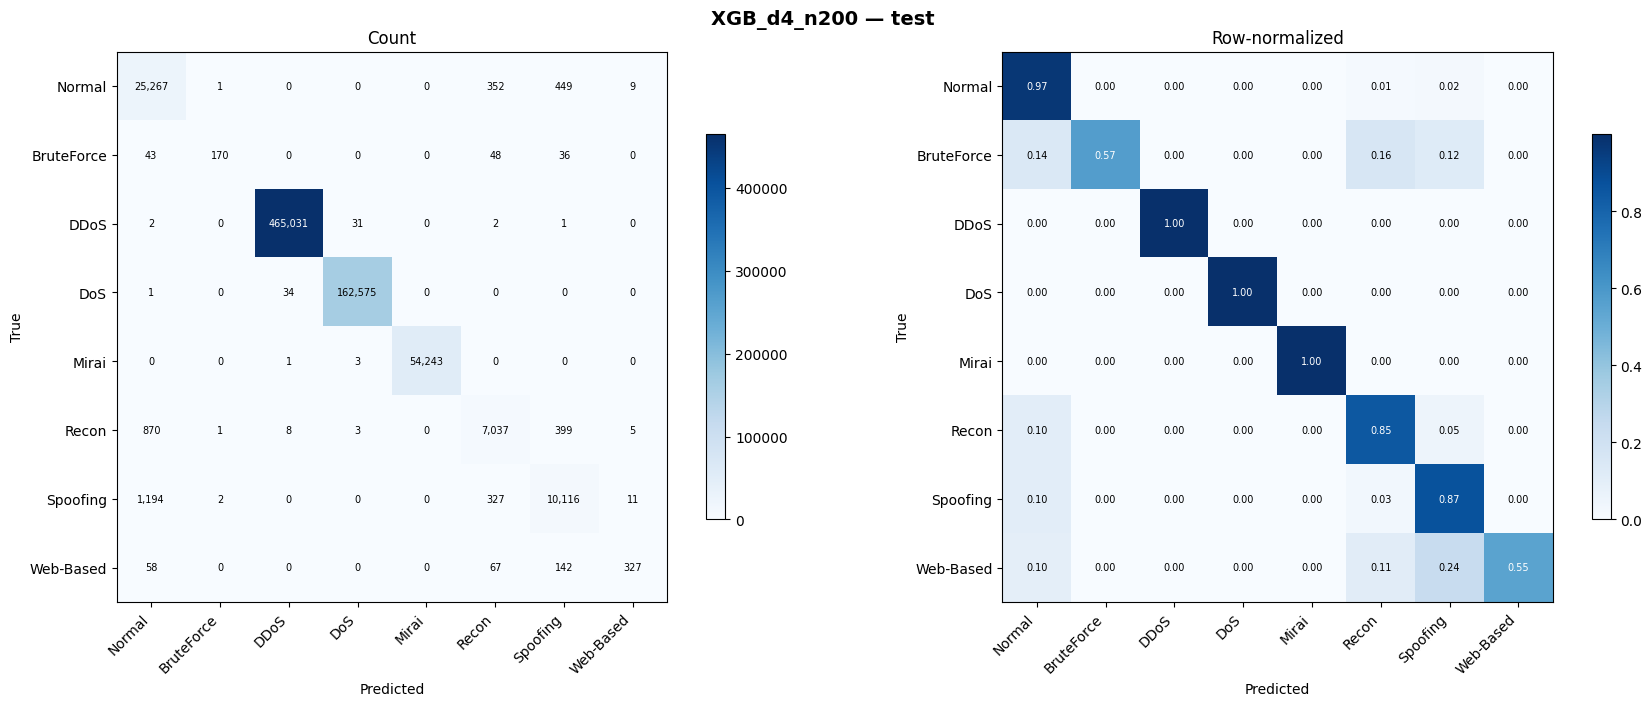


XGB_d4_n200 | TEST
Macro-F1: 0.889495 | Accuracy: 0.994375
Prediction time: 38.81 s | New meta fit: 341.77 s
Inference scope: end-to-end; raw input -> bases -> meta


,Class,precision,recall,f1-score,support
0,Normal,0.92098,0.96890,0.94433,26078.0
1,BruteForce,0.97701,0.57239,0.72187,297.0
2,DDoS,0.99991,0.99992,0.99992,465067.0
3,DoS,0.99977,0.99978,0.99978,162610.0
4,Mirai,1.00000,0.99993,0.99996,54247.0
5,Recon,0.89838,0.84549,0.87113,8323.0
6,Spoofing,0.90783,0.86833,0.88764,11650.0
7,Web-Based,0.92898,0.55051,0.69133,594.0


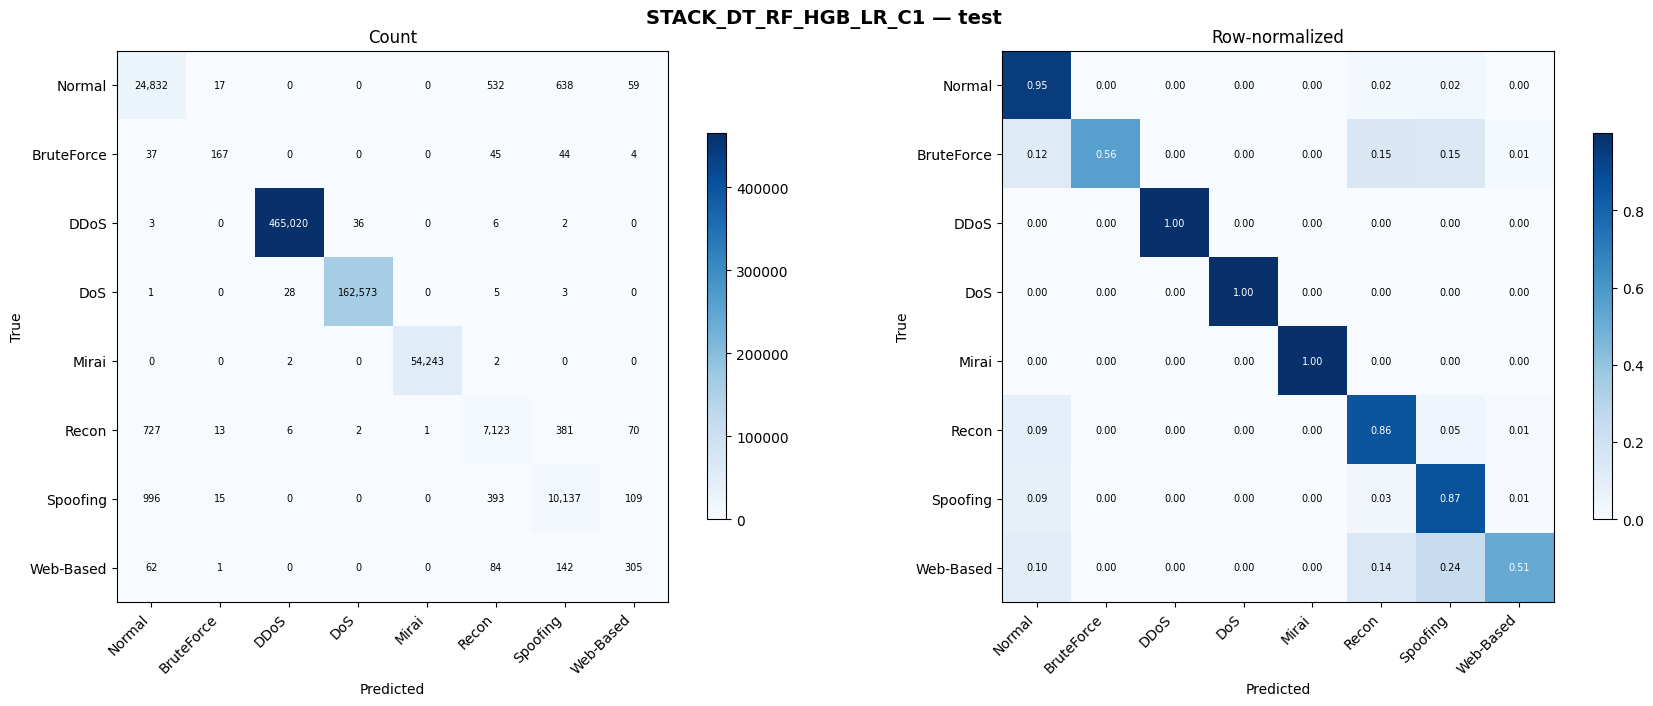


STACK_DT_RF_HGB_LR_C1 | TEST
Macro-F1: 0.859401 | Accuracy: 0.993873
Prediction time: 30.86 s | New meta fit: 0.00 s
Inference scope: end-to-end; raw input -> bases -> meta


,Class,precision,recall,f1-score,support
0,Normal,0.93150,0.95222,0.94175,26078.0
1,BruteForce,0.78404,0.56229,0.65490,297.0
2,DDoS,0.99992,0.99990,0.99991,465067.0
3,DoS,0.99977,0.99977,0.99977,162610.0
4,Mirai,0.99998,0.99993,0.99995,54247.0
5,Recon,0.86972,0.85582,0.86271,8323.0
6,Spoofing,0.89336,0.87013,0.88159,11650.0
7,Web-Based,0.55759,0.51347,0.53462,594.0



REUSED TEST COMPARISON — PRIMARY REMAINS SELECTED ON VALIDATION:


,candidate_id,split,accuracy,macro_f1,weighted_f1,meta_fit_seconds_this_run,predict_seconds,inference_scope,rows,predict_ms_per_row,kind,primary_selected_on_validation,test_previously_viewed
0,XGB_d4_n200,test,0.994375,0.889495,0.994270,341.771302,38.814310,end-to-end; raw input -> bases -> meta,728866,0.053253,xgboost_meta,True,True
1,STACK_DT_RF_HGB_LR_C1,test,0.993873,0.859401,0.993824,0.000000,30.859199,end-to-end; raw input -> bases -> meta,728866,0.042339,baseline_lr,False,True


In [18]:
if (OUTPUT_DIR / "test_comparison.csv").exists():
    raise RuntimeError("Test comparison đã được ghi; không đánh giá lại để chọn cấu hình.")
if not (OUTPUT_DIR / "test_evaluation_started.json").is_file():
    raise RuntimeError("Chạy cell freeze/input audit trước khi dự đoán test.")
test_records = []
for selected in frozen["candidates"]:
    path = OUTPUT_DIR / selected["bundle_file"]
    if sha256_file(path) != selected["sha256"]:
        raise RuntimeError("Frozen bundle thay đổi trước dự đoán test.")
    bundle = prediction_module.load_bundle(path)
    started = time.perf_counter()
    probabilities = prediction_module.predict_bundle(bundle, X_test, BATCH_SIZE)
    elapsed = time.perf_counter() - started
    metrics = evaluate_predictions(
        selected["candidate_id"], "test", y_test, probabilities,
        elapsed, selected["meta_fit_seconds_this_run"], "end-to-end; raw input -> bases -> meta",
    )
    metrics["kind"] = selected["kind"]
    metrics["primary_selected_on_validation"] = selected["candidate_id"] == frozen["primary_candidate_id"]
    metrics["test_previously_viewed"] = True
    test_records.append(metrics)
    del bundle, probabilities
    gc.collect()
test_table = pd.DataFrame(test_records)
test_table.to_csv(OUTPUT_DIR / "test_comparison.csv", index=False)
print("\nREUSED TEST COMPARISON — PRIMARY REMAINS SELECTED ON VALIDATION:")
display(test_table.round(6))

# XGBoost Meta-Model Summary Report


In [19]:
print("=" * 70)
print("PHASE 3B: XGBOOST META-MODEL SUMMARY REPORT")
print("=" * 70)
print(f"Data run       : {DATA_RUN_ID}")
print(f"Source stacking: {SOURCE_RUN_ID}")
print(f"New meta run   : {RUN_ID}")
print(f"Primary        : {frozen['primary_candidate_id']} (selected on validation)")
print("\n[1] VALIDATION — ORIGINAL LR AND NEW XGBOOST")
display(validation_table.round(6))
print("\n[2] REUSED TEST — FROZEN CANDIDATES")
display(test_table.round(6))
print("\n[3] TRAINING COST IN THIS RUN")
print("New base/preprocessor fits: 0")
print("New OOF generation       : 0")
print(f"XGBoost meta fits        : {len(meta_training_records)}")
print(f"Total meta fit time      : {sum(row['meta_fit_seconds'] for row in meta_training_records):,.2f} s")
print("Old OOF/base fit cost belongs to the source run and is not included above.")
print("Validation candidate timings are meta-only; full-pipeline timings are in validation_end_to_end_timing.csv.")
print("Test prediction times include preprocessing, all three base models and meta-model.")
print("\n[4] ARTIFACTS AND CHECKS")
print("OOF/fold alignment, source checksums, original LR reproduction, native JSON reload and golden CSV checks passed.")
print("Standalone bundles: frozen_models/*.joblib; native XGBoost: frozen_models/*.json")
print("Prediction: python predict_csv.py --bundle frozen_models/<id>.joblib --input input.csv --output predictions.csv")
print("Versions/hardware: protocol.json; package versions: requirements.txt")
print("\n[5] LIMITATIONS")
print("Validation/test were already viewed in the source run; this is not an independent confirmation test.")
print("Feature groups do not establish device/session/time independence.")
print("A more flexible meta-model does not guarantee higher macro-F1; selection remains based on validation.")

# Manifest của models/code/report quan trọng để tải về và bàn giao.
output_checksums = {}
for path in sorted(FROZEN_DIR.iterdir()):
    if path.is_file():
        output_checksums[str(path.relative_to(OUTPUT_DIR))] = sha256_file(path)
for file_name in [
    "protocol.json", "source_artifacts.json", "frozen_candidates.json", "validation_comparison.csv",
    "test_comparison.csv", "reload_checks.json", "predict_csv.py", "requirements.txt",
]:
    output_checksums[file_name] = sha256_file(OUTPUT_DIR / file_name)
write_json(OUTPUT_DIR / "output_checksums.json", output_checksums)
write_json(OUTPUT_DIR / "run_status.json", {
    "status": "complete", "run_id": RUN_ID, "protocol": PROTOCOL,
    "source_stacking_run_id": SOURCE_RUN_ID, "data_run_id": DATA_RUN_ID,
    "primary_candidate_id": frozen["primary_candidate_id"],
    "finished_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "total_seconds": round(time.perf_counter() - SESSION_START, 3),
    "test_previously_viewed": True,
})
print(f"\n[OK] XGBOOST META RUN COMPLETED: {OUTPUT_DIR}")

PHASE 3B: XGBOOST META-MODEL SUMMARY REPORT
Data run       : 20261021_052521_96f61f19
Source stacking: stacking_20261021_064141_916da555
New meta run   : xgb_meta_20261021_092334_9024562d
Primary        : XGB_d4_n200 (selected on validation)

[1] VALIDATION — ORIGINAL LR AND NEW XGBOOST


,candidate_id,split,accuracy,macro_f1,weighted_f1,meta_fit_seconds_this_run,predict_seconds,inference_scope,rows,predict_ms_per_row,kind,is_baseline
0,XGB_d4_n200,validation,0.994555,0.896137,0.994463,341.771302,8.807458,meta-only; reused cached base probabilities,755233,0.011662,xgboost_meta,False
1,XGB_d3_n200,validation,0.994508,0.895522,0.994409,340.516469,7.069499,meta-only; reused cached base probabilities,755233,0.009361,xgboost_meta,False
2,XGB_d3_n200_l2_10,validation,0.994516,0.895281,0.994419,326.387080,6.968401,meta-only; reused cached base probabilities,755233,0.009227,xgboost_meta,False
3,XGB_d3_n100,validation,0.994479,0.893833,0.994377,163.697489,3.651481,meta-only; reused cached base probabilities,755233,0.004835,xgboost_meta,False
4,XGB_d2_n100,validation,0.994351,0.890373,0.994245,156.430082,2.564993,meta-only; reused cached base probabilities,755233,0.003396,xgboost_meta,False
5,XGB_d3_n200_rare2,validation,0.994533,0.890140,0.994453,327.322610,6.988706,meta-only; reused cached base probabilities,755233,0.009254,xgboost_meta,False
6,STACK_DT_RF_HGB_LR_C1,validation,0.994154,0.866959,0.994113,0.000000,0.259821,meta-only; reused cached base probabilities,755233,0.000344,baseline_lr,True



[2] REUSED TEST — FROZEN CANDIDATES


,candidate_id,split,accuracy,macro_f1,weighted_f1,meta_fit_seconds_this_run,predict_seconds,inference_scope,rows,predict_ms_per_row,kind,primary_selected_on_validation,test_previously_viewed
0,XGB_d4_n200,test,0.994375,0.889495,0.994270,341.771302,38.814310,end-to-end; raw input -> bases -> meta,728866,0.053253,xgboost_meta,True,True
1,STACK_DT_RF_HGB_LR_C1,test,0.993873,0.859401,0.993824,0.000000,30.859199,end-to-end; raw input -> bases -> meta,728866,0.042339,baseline_lr,False,True



[3] TRAINING COST IN THIS RUN
New base/preprocessor fits: 0
New OOF generation       : 0
XGBoost meta fits        : 6
Total meta fit time      : 1,656.13 s
Old OOF/base fit cost belongs to the source run and is not included above.
Validation candidate timings are meta-only; full-pipeline timings are in validation_end_to_end_timing.csv.
Test prediction times include preprocessing, all three base models and meta-model.

[4] ARTIFACTS AND CHECKS
OOF/fold alignment, source checksums, original LR reproduction, native JSON reload and golden CSV checks passed.
Standalone bundles: frozen_models/*.joblib; native XGBoost: frozen_models/*.json
Prediction: python predict_csv.py --bundle frozen_models/<id>.joblib --input input.csv --output predictions.csv
Versions/hardware: protocol.json; package versions: requirements.txt

[5] LIMITATIONS
Validation/test were already viewed in the source run; this is not an independent confirmation test.
Feature groups do not establish device/session/time indepen